<h1>1. Importing Necessary Libraries & Configuration</h1>

In this step, we import all the required libraries for data manipulation, visualization, deep learning model building (Custom CNN & Transfer Learning), and XAI (Explainable AI) implementation. We also set random seeds for reproducibility.

In [38]:
# --- 1. Core Systems & Utilities ---
import os
import gc               # Garbage collector to save RAM
import time
import random
import math
import warnings
warnings.filterwarnings('ignore')

# --- 2. Data Handling & Numerical Operations ---
import numpy as np
import pandas as pd

# --- 3. Image Processing & Visualization ---
import cv2              # OpenCV
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.cm as cm
import seaborn as sns
import plotly.express as px
from IPython.display import Image, display

# --- 4. Machine Learning Metrics (Scikit-Learn) ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    confusion_matrix, 
    classification_report, 
    roc_curve, 
    auc, 
    precision_recall_fscore_support, 
    accuracy_score
)

# --- 5. Deep Learning Framework (TensorFlow/Keras) ---
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# --- 6. Image Preprocessing Tools ---
from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator, 
    load_img, 
    img_to_array
)

# --- 7. Keras Layers (Functional & Sequential) ---
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, ReLU, MaxPooling2D, 
    Dropout, Flatten, Dense, Input, GlobalAveragePooling2D, Activation
)

# --- 8. Transfer Learning Applications & Specific Preprocessing ---
# 🔥 CRITICAL FIX: Aliasing to avoid NameError and Conflicts 🔥

from tensorflow.keras.applications import ResNet50, MobileNetV2, EfficientNetB0

# ResNet50 Preprocessing (Use 'preprocess_resnet' in your code)
from tensorflow.keras.applications.resnet50 import preprocess_input as preprocess_resnet

# MobileNetV2 Preprocessing (Use 'preprocess_mobile' in your code)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as preprocess_mobile

# EfficientNet Preprocessing (If needed)
from tensorflow.keras.applications.efficientnet import preprocess_input as preprocess_efficientnet

# --- 9. Configuration for Reproducibility ---
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print("All libraries imported successfully!")
print(f"TensorFlow Version: {tf.__version__}")

All libraries imported successfully!
TensorFlow Version: 2.20.0


<h1>2. Data Loading and DataFrame Construction</h1>

In this step, we traverse the dataset directory to collect file paths and associated labels (disease classes). We then construct a Pandas DataFrame to structure this data, which facilitates easy manipulation, analysis, and splitting in subsequent steps.

In [39]:
# Define the dataset directory
base_dir = "/kaggle/input/datasets/jahangirhossainsohag/potato-leaf-disease-in-an-uncontrolled-environment/PotatoLeaf-DiseaseDatasetinUncontrolledEnvironment"

# Get the list of all classes (subdirectories)
folds = os.listdir(base_dir)

# Lists to store file paths and labels
filepaths = []
labels = []

# Iterate through each folder (class) to collect image paths
for fold in folds:
    folder_path = os.path.join(base_dir, fold)
    imgs = os.listdir(folder_path)
    
    # Iterate through each image in the folder
    for img in imgs:
        img_path = os.path.join(folder_path, img)
        filepaths.append(img_path)
        labels.append(fold)

# Create a Pandas DataFrame
df = pd.DataFrame({'filepaths': filepaths, 'labels': labels})

# Display dataset statistics
print(f"Data Loading Complete.")
print(f"Total Images: {len(df)}")
print(f"Total Classes: {len(df['labels'].unique())}")

# Show the first 5 rows of the DataFrame
print("\nSample Data:")
print(df.head())

Data Loading Complete.
Total Images: 3076
Total Classes: 7

Sample Data:
                                           filepaths    labels
0  /kaggle/input/datasets/jahangirhossainsohag/po...  Nematode
1  /kaggle/input/datasets/jahangirhossainsohag/po...  Nematode
2  /kaggle/input/datasets/jahangirhossainsohag/po...  Nematode
3  /kaggle/input/datasets/jahangirhossainsohag/po...  Nematode
4  /kaggle/input/datasets/jahangirhossainsohag/po...  Nematode


<h1>3. Exploratory Data Analysis (EDA)</h1>

In this section, we analyze the dataset to understand the class distribution and visualize sample images. We also examine the RGB color channel distribution to gain insights into the pixel intensity characteristics of the leaf images, which helps in understanding the input data properties.

In [40]:
# --- DataFrame Construction (Using data from Step 2) ---
# Note: In Step 2, we already created 'df'. We can use it directly or rename it.
data = df.copy() # Using the dataframe created in Step 2

print(f"Data Shape: {data.shape}")

Data Shape: (3076, 2)



--- Visualizing Random Sample Images ---


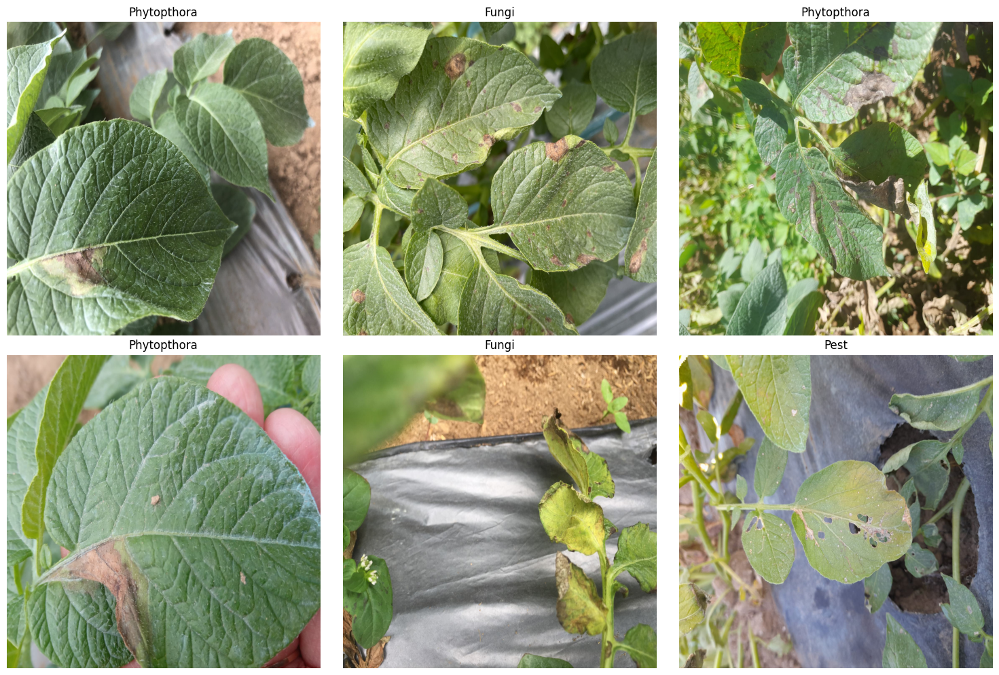

In [41]:
print("\n--- Visualizing Random Sample Images ---")
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i+1)
    rand_idx = np.random.randint(0, len(data))
    img_path = data.iloc[rand_idx]['filepaths']
    lbl = data.iloc[rand_idx]['labels']
    
    # Read and Display Image
    img = plt.imread(img_path)
    plt.imshow(img)
    plt.title(lbl.split('___')[-1], fontsize=12) # Display only the disease name for clarity
    plt.axis('off')

plt.tight_layout()
plt.show()

**🌿 Class Distribution in PlantVillage Dataset**

Data Shape: (3076, 2)


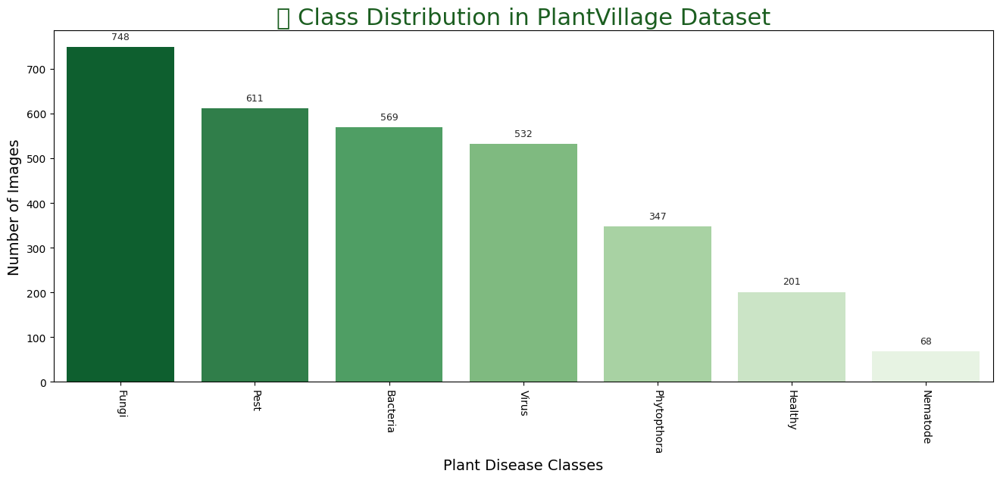

In [42]:
# --- 3.1 DataFrame Construction (Using data from Step 2) ---
# Note: In Step 2, we already created 'df'. We can use it directly or rename it.
data = df.copy() # Using the dataframe created in Step 2

print(f"Data Shape: {data.shape}")


# Prepare data for plotting
label_counts = data['labels'].value_counts().reset_index()
label_counts.columns = ['Label', 'Count']

# Plotting
plt.figure(figsize=(16, 8))
ax = sns.barplot(
    x='Label',
    y='Count',
    data=label_counts,
    palette='Greens_r'
)

# Styling
ax.set_title('🌿 Class Distribution in PlantVillage Dataset', fontsize=22, color='#1b5e20')
ax.set_xlabel("Plant Disease Classes", fontsize=14)
ax.set_ylabel("Number of Images", fontsize=14)
plt.xticks(rotation=-90) # Rotated 90 degrees for better readability if classes are many
plt.subplots_adjust(bottom=0.3)
sns.set_style('whitegrid')

# Add Count Labels on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), 
                textcoords='offset points', fontsize=9)

plt.show()

In [43]:
data.labels.value_counts()


labels
Fungi          748
Pest           611
Bacteria       569
Virus          532
Phytopthora    347
Healthy        201
Nematode        68
Name: count, dtype: int64

**RGB Color Channel Distribution**


🔄 Processing 50 images for Seaborn plot...
✅ 50 images processed. Converting to DataFrame...
📊 Plotting with Seaborn...
💾 Graph saved as 'seaborn_rgb_graph.png'


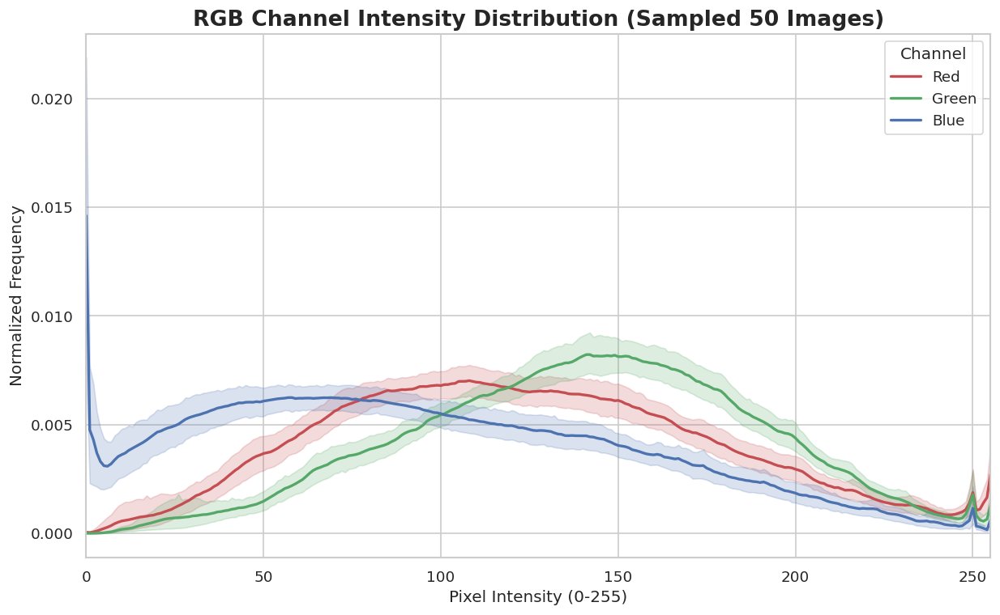

In [44]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# Set Seaborn style (this makes the graph look professional)
sns.set_theme(style="whitegrid")

def plot_rgb_seaborn(df, samples=100):
    print(f"🔄 Processing {samples} images for Seaborn plot...")
    
    if df.empty:
        print("❌ Error: DataFrame is empty!")
        return

    # Select random samples from the dataframe
    sample_indices = np.random.choice(len(df), min(samples, len(df)), replace=False)
    
    # List to store data for plotting
    plot_data = []
    
    valid_count = 0
    
    for idx in sample_indices:
        img_path = df.iloc[idx]['filepaths']
        
        # Check if the file path exists
        if not os.path.exists(img_path):
            continue 
            
        try:
            img = cv.imread(img_path)
            if img is not None:
                img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
                
                # Calculate histograms for 3 channels (Red, Green, Blue)
                r_hist = cv.calcHist([img], [0], None, [256], [0, 256]).flatten()
                g_hist = cv.calcHist([img], [1], None, [256], [0, 256]).flatten()
                b_hist = cv.calcHist([img], [2], None, [256], [0, 256]).flatten()
                
                # Normalize histograms (so all images have the same scale)
                r_hist /= r_hist.sum()
                g_hist /= g_hist.sum()
                b_hist /= b_hist.sum()

                # Prepare data for DataFrame
                # We store all data points so Seaborn can automatically calculate the Mean and Confidence Interval (Shadow)
                for i in range(256):
                    plot_data.append({'Intensity': i, 'Frequency': r_hist[i], 'Channel': 'Red'})
                    plot_data.append({'Intensity': i, 'Frequency': g_hist[i], 'Channel': 'Green'})
                    plot_data.append({'Intensity': i, 'Frequency': b_hist[i], 'Channel': 'Blue'})
                
                valid_count += 1
        except Exception as e:
            print(f"Skipping error: {e}")

    if valid_count == 0:
        print("\n❌ Error: No images loaded! Please check file paths.")
        return

    print(f"✅ {valid_count} images processed. Converting to DataFrame...")
    
    # Create Pandas DataFrame from the list
    vis_df = pd.DataFrame(plot_data)

    print("📊 Plotting with Seaborn...")

    # --- SEABORN PLOTTING ---
    plt.figure(figsize=(12, 7), dpi=120)
    
    # Using lineplot allows Seaborn to automatically show the 'Shadow' (Confidence Interval)
    # This gives the graph a high-quality research paper look
    sns.lineplot(data=vis_df, x='Intensity', y='Frequency', hue='Channel', 
                 palette={'Red': 'r', 'Green': 'g', 'Blue': 'b'}, linewidth=2)

    plt.title(f'RGB Channel Intensity Distribution (Sampled {valid_count} Images)', fontsize=16, fontweight='bold')
    plt.xlabel('Pixel Intensity (0-255)', fontsize=12)
    plt.ylabel('Normalized Frequency', fontsize=12)
    plt.xlim(0, 255)
    
    # Save the graph
    plt.savefig('seaborn_rgb_graph.png', bbox_inches='tight')
    print("💾 Graph saved as 'seaborn_rgb_graph.png'")
    
    plt.show()

# Call the function
# Note: Keep samples=50 or 100. Higher values may take more time due to Seaborn calculations.
plot_rgb_seaborn(data, samples=50)

Observations from EDA

1. **Class Distribution:** The potato leaf disease dataset contains three classes: **Early Blight, Late Blight, and Healthy**. The number of images in each class is relatively balanced, allowing the model to learn effectively without significant bias. If any minor imbalance exists, data augmentation can be applied to improve class representation.

2. **Pixel Intensity:** The RGB channel analysis indicates that the **Green** channel has the highest average intensity, which is expected because potato leaf images contain a large amount of green vegetation. Additionally, the presence of black pixels (intensity 0) is due to the segmented black backgrounds commonly found in the PlantVillage dataset.

3. **Image Quality:** Most images have a consistent resolution and clear leaf segmentation, making them suitable for deep learning models. The uniform background helps the model focus on disease-related features instead of irrelevant objects.

4. **Disease Characteristics:** Visual inspection shows distinct symptoms across the classes. **Early Blight** images exhibit brown circular lesions with concentric rings, **Late Blight** images contain dark, water-soaked irregular patches, while **Healthy** leaves maintain a uniform green appearance with no visible disease symptoms.

<h1>4. Splitting Data into Train, Validation, and Test Sets</h1>

To ensure a robust evaluation, we split the dataset into three parts:


1. **Training Set (80%):** Used to train the model.
2. **Validation Set (10%):** Used to tune hyperparameters and monitor overfitting during training.
3. **Test Set (10%):** Kept completely unseen to evaluate the final model's performance and for XAI validation.

We employ stratified sampling to maintain the same class distribution across all splits, which is critical given the class imbalance observed in the EDA.

**Data Splitting: Train, Validation, and Test Sets**


In [45]:
# --- Splitting Strategy ---
# First, split into Training (80%) and Temporary (20%) sets
# 'stratify' ensures that the proportion of each class matches the original dataset
train_data, temp_data = train_test_split(
    data, 
    test_size=0.2, 
    shuffle=True, 
    stratify=data['labels'], 
    random_state=42
)

# Next, split the Temporary set equally into Validation (10%) and Test (10%) sets
valid_data, test_data = train_test_split(
    temp_data, 
    test_size=0.5, 
    shuffle=True, 
    stratify=temp_data['labels'], 
    random_state=42
)

In [46]:
# --- Verification ---
print("--- Data Split Statistics ---")
print(f"Training Set:   {train_data.shape[0]} images (80%)")
print(f"Validation Set: {valid_data.shape[0]} images (10%)")
print(f"Test Set:       {test_data.shape[0]} images (10%)")

--- Data Split Statistics ---
Training Set:   2460 images (80%)
Validation Set: 308 images (10%)
Test Set:       308 images (10%)


In [47]:
# --- Integrity Check ---
# Ensure all classes are present in all sets (Crucial for rare classes)
train_classes = len(train_data.labels.value_counts())
valid_classes = len(valid_data.labels.value_counts())
test_classes = len(test_data.labels.value_counts())
total_classes = len(data.labels.unique())

print(f"\n--- Class Integrity Check ---")
print(f"Total Unique Classes: {total_classes}")
print(f"Classes in Train:     {train_classes}")
print(f"Classes in Valid:     {valid_classes}")
print(f"Classes in Test:      {test_classes}")

# Assert that all sets have all classes (This will throw an error if something is wrong)
assert train_classes == total_classes, "Error: Missing classes in Training Set"
assert valid_classes == total_classes, "Error: Missing classes in Validation Set"
assert test_classes == total_classes, "Error: Missing classes in Test Set"

print("\nSuccess: Stratified split completed successfully. All classes represented in all sets.")


--- Class Integrity Check ---
Total Unique Classes: 7
Classes in Train:     7
Classes in Valid:     7
Classes in Test:      7

Success: Stratified split completed successfully. All classes represented in all sets.


<h1>5. Data Preprocessing and Augmentation</h1>
In this step, we initialize ImageDataGenerator for dynamic data loading.

* **Training Data:** We apply **Data Augmentation** techniques (rotation, zooming, horizontal flipping, shifting) to artificially increase the diversity of the training set. This helps prevent overfitting, especially for classes with fewer samples.

* **Validation & Test Data:** These are only rescaled (normalized to 0-1 range) without any distortion to ensure accurate evaluation on real-world images.

In [48]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224)  # Standard input size for most Deep Learning models
CHANNELS = 3  

In [49]:
# --- 1. Training Generator (With Augmentation) ---
train_datagen = ImageDataGenerator(
    rescale=1./255,             # Normalize pixel values [0, 255] -> [0, 1]
    rotation_range=20,          # Random rotation between -20 to +20 degrees
    width_shift_range=0.2,      # Horizontal shift
    height_shift_range=0.2,     # Vertical shift
    zoom_range=0.2,             # Random zoom
    horizontal_flip=True,       # Horizontal flipping
    fill_mode='nearest'         # Handling newly created pixels
)

In [50]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Validation & Test Generator
test_datagen = ImageDataGenerator(
    rescale=1./255
)

print(test_datagen)

In [51]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# --- 2. Validation & Test Generator (Rescale Only) ---
# No augmentation for validation/test to maintain data integrity
test_datagen = ImageDataGenerator(rescale=1./255)

In [52]:
# --- 3. Flow from DataFrame ---
print("--- Loading Training Data ---")
train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=True,              # Important for training
    seed=42
)

print("\n--- Loading Validation Data ---")
valid_gen = test_datagen.flow_from_dataframe(
    dataframe=valid_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=False,             # Usually False for validation to keep order stable
    seed=42
)

print("\n--- Loading Test Data ---")
test_gen = test_datagen.flow_from_dataframe(
    dataframe=test_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=False              # CRITICAL: Must be False for correct confusion matrix later
)

--- Loading Training Data ---
Found 2460 validated image filenames belonging to 7 classes.

--- Loading Validation Data ---
Found 308 validated image filenames belonging to 7 classes.

--- Loading Test Data ---
Found 308 validated image filenames belonging to 7 classes.


In [53]:
# --- Verify Generator Output ---
# Check the shape of one batch
images, labels = next(train_gen)
print(f"\nBatch Shape Check: {images.shape}")  # Should be (32, 224, 224, 3)
print(f"Label Shape Check: {labels.shape}")  # Should be (32, 38)


Batch Shape Check: (32, 224, 224, 3)
Label Shape Check: (32, 7)


<h2>5.1 Class Mapping Verification</h2>
Here we verify the mapping between the class names (strings) and the integer labels (indices) assigned by the generator. This mapping is essential for interpreting the model's predictions and plotting the confusion matrix later.

In [54]:
# 5.1 Check Class Label Mappings

# Get the dictionary of class indices
class_indices = train_gen.class_indices
print("--- Class Names and Assigned Indices ---")

# Print them nicely
for class_name, class_index in class_indices.items():
    print(f"Index {class_index}: {class_name}")

print("\n--- Iteration completed. Mapping is correct. ---")

# Save the class names as a list for later use (e.g., in Classification Report)
class_names = list(class_indices.keys())
print(f"\nStored {len(class_names)} class names for future reference.")

--- Class Names and Assigned Indices ---
Index 0: Bacteria
Index 1: Fungi
Index 2: Healthy
Index 3: Nematode
Index 4: Pest
Index 5: Phytopthora
Index 6: Virus

--- Iteration completed. Mapping is correct. ---

Stored 7 class names for future reference.


<h1>6. Proposed Custom CNN Architecture</h1>
In this phase, we design and train a custom Convolutional Neural Network (CNN) tailored for plant disease detection. Unlike standard CNNs, this architecture incorporates several modern deep learning optimizations to ensure high accuracy while maintaining computational efficiency:


* **Swish Activation:** We replace the traditional ReLU activation with **Swish ( f(x)=x⋅sigmoid(x)**. Swish allows for better gradient flow during backpropagation, helping the model learn complex patterns more effectively.
  
* **Global Average Pooling (GAP):** Instead of using a traditional Flatten layer which generates millions of parameters, we use GlobalAveragePooling2D. This drastically reduces the model size and minimizes the risk of overfitting.

* **Label Smoothing:** We utilize **Label Smoothing** (0.1) in the loss function. This prevents the model from becoming overconfident in its predictions, thereby improving its ability to generalize to unseen data (Test Set).

**Custom CNN Model Implementation**

In [55]:
# 6. Custom CNN Model Implementation

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, MaxPooling2D, Dropout, 
    Dense, GlobalAveragePooling2D, Activation, InputLayer
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import os

In [56]:
# --- Configuration ---
NUM_CLASSES = len(train_gen.class_indices)
IMG_SHAPE = (IMG_SIZE[0], IMG_SIZE[1], 3)
EPOCHS = 15

In [57]:
# ============================================================
# Lightweight Custom CNN
# ============================================================

# --- Model Architecture ---
model = Sequential([
    InputLayer(input_shape=IMG_SHAPE),
    
    # --- Block 1: Feature Extraction (Low Level) ---
    Conv2D(16, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('swish'), # Swish is often superior to ReLU in deep networks

    Conv2D(32, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('swish'),

    MaxPooling2D((2, 2)),
    Dropout(0.20),


    # =====================
    # --- Block 2: Feature Extraction (Mid Level) ---
    # =====================
    Conv2D(32, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('swish'),

    Conv2D(64, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('swish'),

    MaxPooling2D((2, 2)),
    Dropout(0.20),


    # =====================
    # -- Block 3: Feature Extraction (High Level) ---
    # =====================
    Conv2D(64, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('swish'),

    Conv2D(128, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('swish'),

    MaxPooling2D((2, 2)),
    Dropout(0.25),


    # =====================
    # --- Classification Head (Optimized) ---
    # GlobalAveragePooling2D reduces parameters significantly compared to Flatten()
    # =====================
    GlobalAveragePooling2D(),

    Dense(128),
    BatchNormalization(),
    Activation('swish'),
    Dropout(0.40),

    Dense(NUM_CLASSES, activation='softmax')
])


# =========================
# Model Summary
# =========================
model.summary()

2026-08-25 12:47:35.195689: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             

 Total params: 162,887 (636.28 KB)

 Trainable params: 161,959 (632.65 KB)

 Non-trainable params: 928 (3.62 KB)

In [58]:
# --- Compilation ---
print("\n--- Compiling the model with Label Smoothing ---")
model.compile(
    optimizer=Adam(learning_rate=0.001),
    # Label smoothing helps the model generalize better by penalizing overconfidence
    loss=CategoricalCrossentropy(label_smoothing=0.1), 
    metrics=['accuracy']
)


--- Compiling the model with Label Smoothing ---


In [59]:
# --- Callbacks Setup ---
checkpoint_dir = "/kaggle/working/model_checkpoints/"
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_filepath = os.path.join(checkpoint_dir, "explainable_cnn_model.keras")

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.00001,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_filepath,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

In [60]:
# --- Training ---
print("\n--- Starting Training Process ---")
history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=valid_gen,
    callbacks=callbacks,
    verbose=1
)


--- Starting Training Process ---
Epoch 1/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.2848 - loss: 1.9636
Epoch 1: val_loss improved from None to 1.95092, saving model to /kaggle/working/model_checkpoints/explainable_cnn_model.keras

Epoch 1: finished saving model to /kaggle/working/model_checkpoints/explainable_cnn_model.keras
77/77 ━━━━━━━━━━━━━━━━━━━━ 532s 7s/step - accuracy: 0.3317 - loss: 1.8469 - val_accuracy: 0.1981 - val_loss: 1.9509 - learning_rate: 0.0010
Epoch 2/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.4122 - loss: 1.6722
Epoch 2: val_loss did not improve from 1.95092
77/77 ━━━━━━━━━━━━━━━━━━━━ 523s 7s/step - accuracy: 0.4057 - loss: 1.6646 - val_accuracy: 0.2435 - val_loss: 2.0859 - learning_rate: 0.0010
Epoch 3/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.4424 - loss: 1.5931
Epoch 3: val_loss did not improve from 1.95092
77/77 ━━━━━━━━━━━━━━━━━━━━ 519s 7s/step - accuracy: 0.4329 - loss: 1.6124 - val_accuracy: 0.2435 - val_loss: 2.1156 - 

<h2>6.1: Visualizing Training Results (Graphs)</h2>

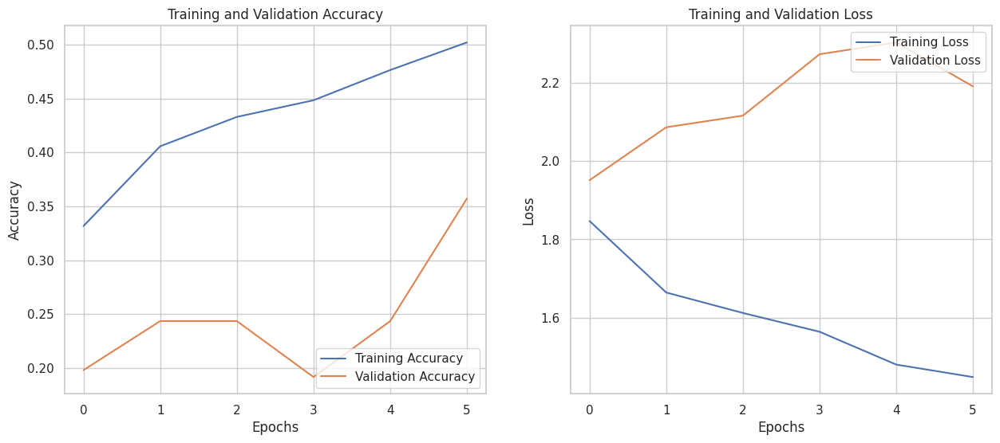

In [61]:
# 6.1 Visualize Training History

def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(15, 6))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    
    plt.show()

# Plot the graphs
plot_training_history(history)

<h2>6.2 Model Evaluation on Test Set</h2>

After training, we evaluate the best-saved model on the unseen Test Set (10% of data). This step provides the unbiased performance metrics required for the thesis conclusion. We also generate a **Confusion Matrix** to visualize misclassifications and a **Classification Report** for class-wise Precision, Recall, and F1-Scores.

--- Evaluating on Test Set ---
10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.1981 - loss: 1.9508

Test Accuracy: 19.81%
Test Loss: 1.9508
10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step


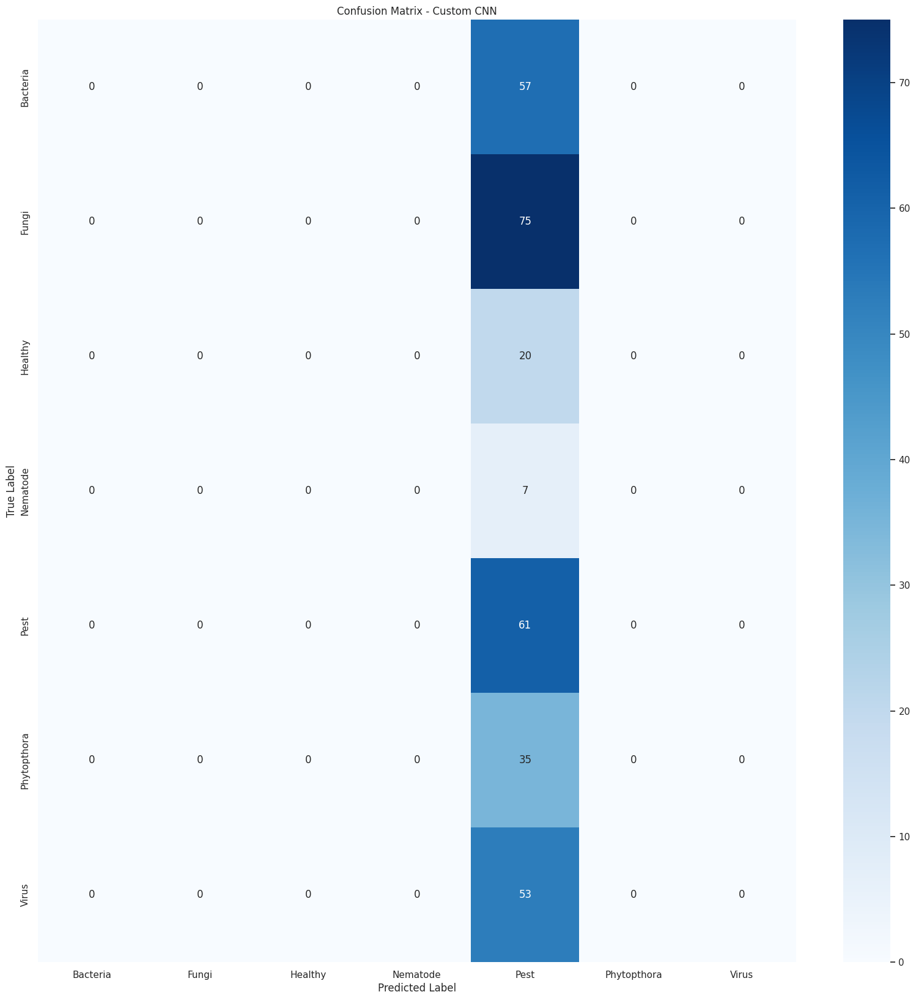


--- Classification Report ---
              precision    recall  f1-score   support

    Bacteria       0.00      0.00      0.00        57
       Fungi       0.00      0.00      0.00        75
     Healthy       0.00      0.00      0.00        20
    Nematode       0.00      0.00      0.00         7
        Pest       0.20      1.00      0.33        61
 Phytopthora       0.00      0.00      0.00        35
       Virus       0.00      0.00      0.00        53

    accuracy                           0.20       308
   macro avg       0.03      0.14      0.05       308
weighted avg       0.04      0.20      0.07       308



In [62]:
# 6.2 Evaluate on Test Data

# 1. Load the best saved model (Crucial step!)
# We must load the checkpoint because the final epoch model might not be the best one.
best_model = tf.keras.models.load_model("/kaggle/working/model_checkpoints/explainable_cnn_model.keras")

print("--- Evaluating on Test Set ---")
test_loss, test_acc = best_model.evaluate(test_gen)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# 2. Generate Predictions
# We reset the generator to ensure we start from the first image
test_gen.reset()
predictions = best_model.predict(test_gen, verbose=1)

# Convert probabilities to class indices (e.g., [0.1, 0.9] -> 1)
predicted_indices = np.argmax(predictions, axis=1)

# Get true labels from the generator
true_indices = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# 3. Confusion Matrix
cm = confusion_matrix(true_indices, predicted_indices)

plt.figure(figsize=(20, 20))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Custom CNN')
plt.show()

# 4. Classification Report
print("\n--- Classification Report ---")
report = classification_report(true_indices, predicted_indices, target_names=class_labels)
print(report)

**Visualizing Random Sample Predictions using Custom CNN**


--- Loading Custom CNN Model ---


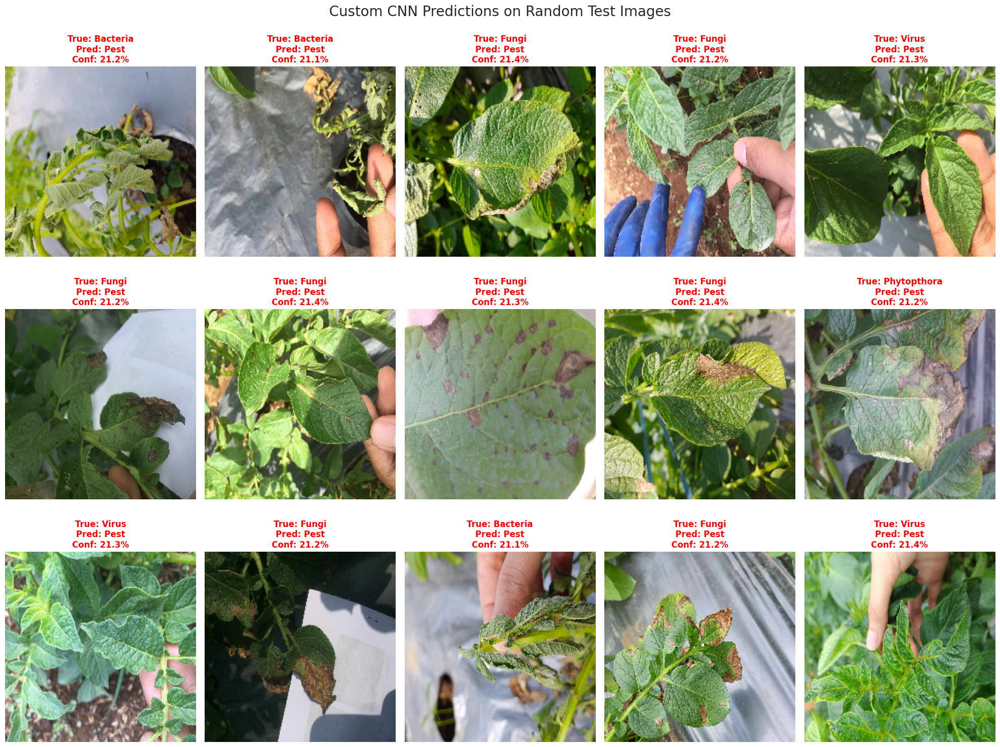

In [63]:
# Visualizing Random Sample Predictions using Custom CNN

# 1. Load the Best Custom CNN Model
print("--- Loading Custom CNN Model ---")
model_pred = tf.keras.models.load_model("/kaggle/working/model_checkpoints/explainable_cnn_model.keras")

# 2. Get Class Labels (Index -> Name)
# train_gen.class_indices gives {'Apple___Black_rot': 0, ...}
# We need {0: 'Apple___Black_rot', ...} to decode predictions
class_map = {v: k for k, v in train_gen.class_indices.items()}

# 3. Select Random Images from Test Data
# We will pick 15 random images to display
num_samples = 15
random_indices = np.random.choice(len(test_data), num_samples, replace=False)

plt.figure(figsize=(20, 15))

for i, idx in enumerate(random_indices):
    # Get image path and true label from dataframe
    row = test_data.iloc[idx]
    img_path = row['filepaths']
    true_label = row['labels']
    
    # --- Preprocessing (Crucial for Custom CNN) ---
    # Load Image
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    
    # Expand dims (1, 224, 224, 3)
    img_batch = np.expand_dims(img_array, axis=0)
    
    # Normalize: Custom CNN was trained with 1./255, so we MUST divide by 255.0
    img_batch = img_batch / 255.0
    
    # --- Prediction ---
    prediction = model_pred.predict(img_batch, verbose=0)
    pred_idx = np.argmax(prediction)  # Get index of highest probability
    pred_label = class_map[pred_idx]  # Convert index to name
    confidence = np.max(prediction) * 100 # Get confidence percentage
    
    # --- Plotting ---
    plt.subplot(3, 5, i + 1)
    plt.imshow(img_array.astype('uint8')) # Show original image
    
    # Color logic: Green if correct, Red if wrong
    color = 'green' if true_label == pred_label else 'red'
    
    # Clean up the label name (remove '___' for better display)
    title_true = true_label.split('___')[-1]
    title_pred = pred_label.split('___')[-1]
    
    plt.title(f"True: {title_true}\nPred: {title_pred}\nConf: {confidence:.1f}%", 
              color=color, fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.suptitle("Custom CNN Predictions on Random Test Images", fontsize=20, y=1.02)
plt.show()

<h1>7. Transfer Learning using ResNet50</h1>

To benchmark our proposed Custom CNN, we implement **ResNet50**, a standard deep learning architecture pre-trained on the ImageNet dataset. We utilize a **Feature Extraction** strategy:

1. **Base Model:** We load the ResNet50 model without its top classification layer (include_top=False) and freeze its weights (trainable=False). This allows us to reuse the robust feature extractors learned from millions of images.

2. **Custom Head:** We attach a lightweight classification head (GlobalAveragePooling + Dense Layers) similar to our custom model to adapt the pre-trained features for plant disease classification.

<h2>Step 7.1: Reload Data Generators (Crucial for ResNet)</h2>



In [64]:
# 7.1 Preprocessing Setup for ResNet50
# ResNet50 requires specific input preprocessing (not just 1/255 scaling).
# We must reload the generators using the 'preprocess_input' function.

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

# --- 1. Training Generator (ResNet Specific) ---
train_datagen_resnet = ImageDataGenerator(
    preprocessing_function=preprocess_resnet, # <--- KEY CHANGE
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# --- 2. Validation Generator (ResNet Specific) ---
test_datagen_resnet = ImageDataGenerator(
    preprocessing_function=preprocess_resnet  # <--- KEY CHANGE
)

# --- 3. Reload Data ---
print("--- Reloading Data for ResNet50 ---")

train_gen_resnet = train_datagen_resnet.flow_from_dataframe(
    dataframe=train_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

valid_gen_resnet = test_datagen_resnet.flow_from_dataframe(
    dataframe=valid_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=42
)

--- Reloading Data for ResNet50 ---
Found 2460 validated image filenames belonging to 7 classes.
Found 308 validated image filenames belonging to 7 classes.


<h2>Step 7.2: ResNet50 Model Implementation</h2>



In [65]:
# --- Configuration ---
IMG_SHAPE = (224, 224, 3)
NUM_CLASSES = len(train_gen.class_indices)
EPOCHS_TL = 10

print("Number of Classes:", NUM_CLASSES)
print("Classes:", train_gen.class_indices)


# --- Model Architecture ---

# 1. Load ResNet50 WITHOUT downloading ImageNet weights
base_model = ResNet50(
    weights=None,
    include_top=False,
    input_shape=IMG_SHAPE
)

# 2. Freeze Base Model
base_model.trainable = False

# 3. Classification Head
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(64)(x)
x = BatchNormalization()(x)
x = Activation("swish")(x)
x = Dropout(0.3)(x)

# 4. Output Layer
predictions = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

# 5. Final Model
resnet_model = Model(
    inputs=base_model.input,
    outputs=predictions
)

# Display model architecture
resnet_model.summary()

print(f"ResNet50 Initialized. Total Layers: {len(resnet_model.layers)}")

Number of Classes: 7
Classes: {'Bacteria': 0, 'Fungi': 1, 'Healthy': 2, 'Nematode': 3, 'Pest': 4, 'Phytopthora': 5, 'Virus': 6}


Model: "functional_61"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,719,559 (90.48 MB)

 Trainable params: 131,719 (514.53 KB)

 Non-trainable params: 23,587,840 (89.98 MB)

ResNet50 Initialized. Total Layers: 181


In [66]:
# --- Compilation ---
print("\n--- Compiling ResNet50 with Label Smoothing ---")
resnet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=CategoricalCrossentropy(label_smoothing=0.1), 
    metrics=['accuracy']
)


--- Compiling ResNet50 with Label Smoothing ---


In [67]:
# --- Callbacks Setup ---
# Note: We changed the filename to 'best_resnet50.keras' to avoid overwriting the Custom CNN
checkpoint_dir = "/kaggle/working/model_checkpoints/"
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_filepath_resnet = os.path.join(checkpoint_dir, "best_resnet50.keras")

callbacks_resnet = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.00001,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=checkpoint_filepath_resnet,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

In [68]:
# --- Training ---
print("\n--- Starting ResNet50 Training Process ---")
history_resnet = resnet_model.fit(
    train_gen_resnet,            # Using the NEW generator
    epochs=EPOCHS_TL,
    validation_data=valid_gen_resnet, # Using the NEW generator
    callbacks=callbacks_resnet,
    verbose=1
)


--- Starting ResNet50 Training Process ---
Epoch 1/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.2883 - loss: 1.9452
Epoch 1: val_loss improved from None to 3.89460, saving model to /kaggle/working/model_checkpoints/best_resnet50.keras

Epoch 1: finished saving model to /kaggle/working/model_checkpoints/best_resnet50.keras
77/77 ━━━━━━━━━━━━━━━━━━━━ 264s 3s/step - accuracy: 0.3138 - loss: 1.8684 - val_accuracy: 0.2565 - val_loss: 3.8946 - learning_rate: 0.0010
Epoch 2/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.3334 - loss: 1.7810
Epoch 2: val_loss improved from 3.89460 to 3.63275, saving model to /kaggle/working/model_checkpoints/best_resnet50.keras

Epoch 2: finished saving model to /kaggle/working/model_checkpoints/best_resnet50.keras
77/77 ━━━━━━━━━━━━━━━━━━━━ 245s 3s/step - accuracy: 0.3419 - loss: 1.7652 - val_accuracy: 0.2403 - val_loss: 3.6328 - learning_rate: 0.0010
Epoch 3/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.3853 - loss: 1.7346
Epoch 3:

<h2>Step 7.3: Visualizing Training History (Graphs)</h2>



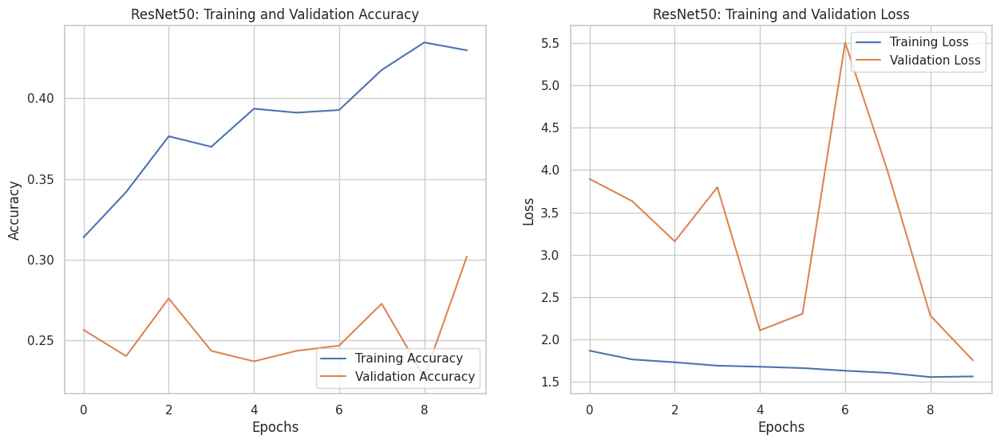

In [69]:
# 7.3 Visualize ResNet50 Training History

import matplotlib.pyplot as plt

def plot_training_history_resnet(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(15, 6))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('ResNet50: Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('ResNet50: Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    
    plt.show()

# Plot the graphs for ResNet
plot_training_history_resnet(history_resnet)

<h2>Step 7.4: Model Evaluation on Test Set</h2>

We evaluate the fine-tuned ResNet50 model on the independent test set. Crucial Step: The test data is preprocessed using the specific preprocess_input function required by ResNet50 to ensure consistent feature scaling.

--- Loading Test Data for ResNet50 ---
Found 308 validated image filenames belonging to 7 classes.

--- Loading Best ResNet50 Checkpoint ---

--- Evaluating on Test Set ---
10/10 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - accuracy: 0.3182 - loss: 1.7336

ResNet50 Test Accuracy: 31.82%
ResNet50 Test Loss: 1.7336
10/10 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step


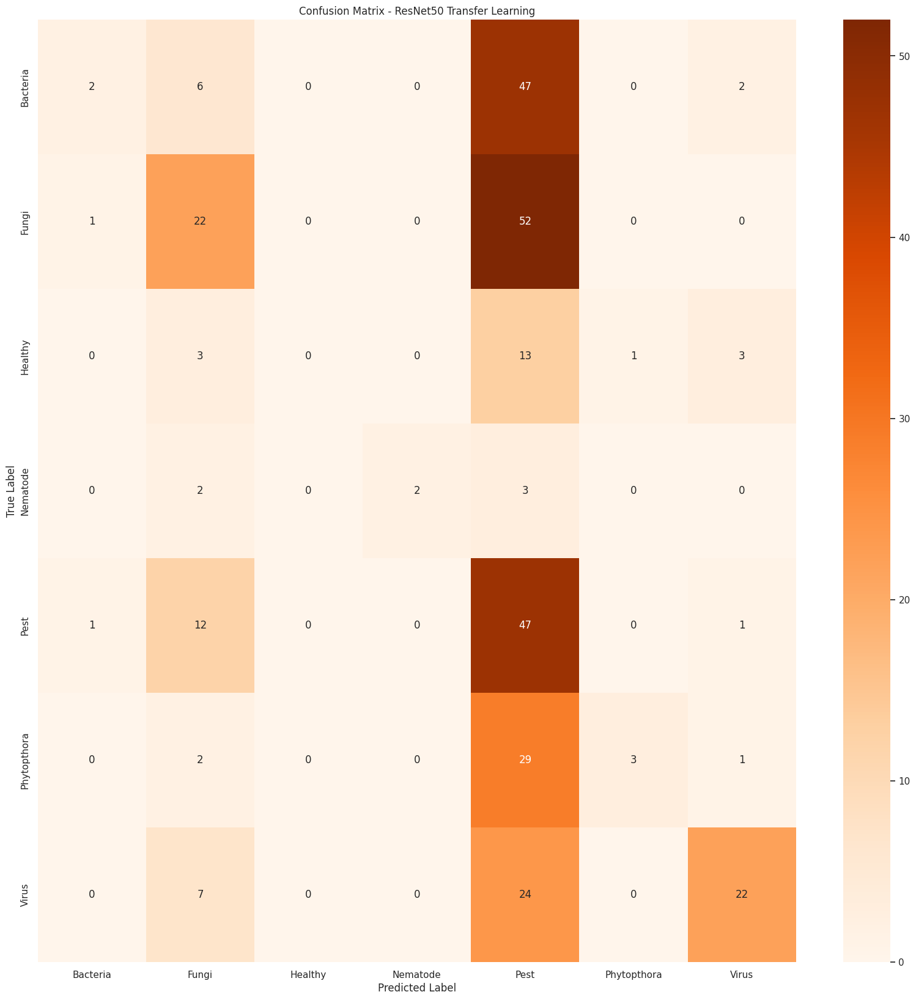


--- ResNet50 Classification Report ---
              precision    recall  f1-score   support

    Bacteria       0.50      0.04      0.07        57
       Fungi       0.41      0.29      0.34        75
     Healthy       0.00      0.00      0.00        20
    Nematode       1.00      0.29      0.44         7
        Pest       0.22      0.77      0.34        61
 Phytopthora       0.75      0.09      0.15        35
       Virus       0.76      0.42      0.54        53

    accuracy                           0.32       308
   macro avg       0.52      0.27      0.27       308
weighted avg       0.47      0.32      0.28       308



In [70]:
# 7.4 Evaluate ResNet50 on Test Data

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np

# --- 1. Prepare Test Generator for ResNet (Crucial!) ---
# We cannot use the old test_gen because ResNet needs specific preprocessing
test_datagen_resnet = ImageDataGenerator(
    preprocessing_function=preprocess_resnet # <--- Must match training preprocessing
)

print("--- Loading Test Data for ResNet50 ---")
test_gen_resnet = test_datagen_resnet.flow_from_dataframe(
    dataframe=test_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=False,  # Important for Confusion Matrix
    seed=42
)

# --- 2. Load the Best Saved ResNet Model ---
print("\n--- Loading Best ResNet50 Checkpoint ---")
best_resnet_model = tf.keras.models.load_model("/kaggle/working/model_checkpoints/best_resnet50.keras")

# --- 3. Evaluate ---
print("\n--- Evaluating on Test Set ---")
test_loss, test_acc = best_resnet_model.evaluate(test_gen_resnet)
print(f"\nResNet50 Test Accuracy: {test_acc * 100:.2f}%")
print(f"ResNet50 Test Loss: {test_loss:.4f}")

# --- 4. Generate Predictions & Confusion Matrix ---
test_gen_resnet.reset()
predictions = best_resnet_model.predict(test_gen_resnet, verbose=1)
predicted_indices = np.argmax(predictions, axis=1)
true_indices = test_gen_resnet.classes
class_labels = list(test_gen_resnet.class_indices.keys())

# Plot Confusion Matrix
cm = confusion_matrix(true_indices, predicted_indices)
plt.figure(figsize=(20, 20))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - ResNet50 Transfer Learning')
plt.show()

# --- 5. Classification Report ---
print("\n--- ResNet50 Classification Report ---")
print(classification_report(true_indices, predicted_indices, target_names=class_labels))

--- Loading ResNet50 Model ---


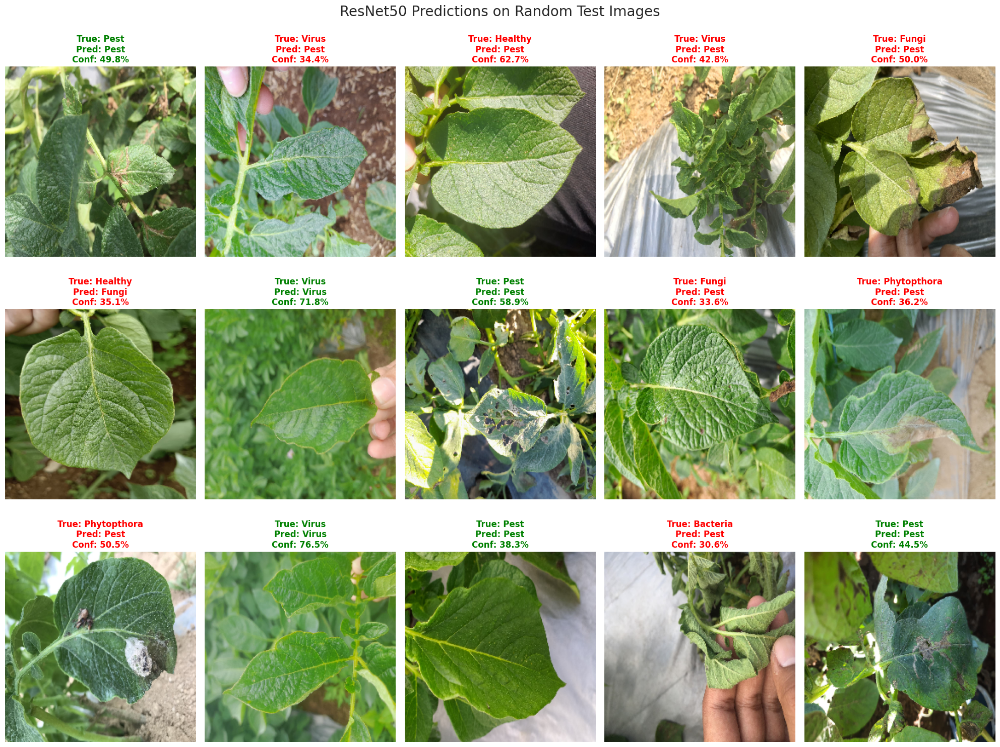

In [71]:
# 1. Load the Best ResNet50 Model
print("--- Loading ResNet50 Model ---")
model_resnet_pred = tf.keras.models.load_model("/kaggle/working/model_checkpoints/best_resnet50.keras")

# 2. Get Class Labels
class_map = {v: k for k, v in train_gen.class_indices.items()}

# 3. Select Random Images
num_samples = 15
random_indices = np.random.choice(len(test_data), num_samples, replace=False)

plt.figure(figsize=(20, 15))

for i, idx in enumerate(random_indices):
    # Get image path and true label
    row = test_data.iloc[idx]
    img_path = row['filepaths']
    true_label = row['labels']
    
    # --- Image Loading ---
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    
    # --- Preprocessing for ResNet (Difference is HERE) ---
    # We need two versions:
    # 1. 'display_img' for showing in matplotlib (needs to be standard RGB)
    # 2. 'pred_img' for the model (needs specific ResNet preprocessing)
    
    display_img = img_array.astype('uint8') # Keep original for display
    
    pred_img = img_array.copy() # Make a copy for preprocessing
    pred_img = np.expand_dims(pred_img, axis=0) # Shape: (1, 224, 224, 3)
    pred_img = preprocess_resnet(pred_img) # <--- Apply ResNet Magic
    
    # --- Prediction ---
    prediction = model_resnet_pred.predict(pred_img, verbose=0)
    pred_idx = np.argmax(prediction)
    pred_label = class_map[pred_idx]
    confidence = np.max(prediction) * 100
    
    # --- Plotting ---
    plt.subplot(3, 5, i + 1)
    plt.imshow(display_img) # Show the normal image
    
    # Logic: Green if correct, Red if wrong
    color = 'green' if true_label == pred_label else 'red'
    
    title_true = true_label.split('___')[-1]
    title_pred = pred_label.split('___')[-1]
    
    plt.title(f"True: {title_true}\nPred: {title_pred}\nConf: {confidence:.1f}%", 
              color=color, fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.suptitle("ResNet50 Predictions on Random Test Images", fontsize=20, y=1.02)
plt.show()

<h1>8. Transfer Learning with MobileNetV2</h1>
Finally, we evaluate MobileNetV2, a lightweight architecture optimized for mobile and edge devices. It utilizes Depthwise Separable Convolutions to reduce the number of parameters and computation cost significantly.

We apply the same transfer learning strategy:

Preprocessing: Inputs are scaled to [-1, 1] using MobileNetV2's specific preprocessing function.
Feature Extraction: The pre-trained base is frozen to act as a robust feature extractor.
Head: The same custom classification head is attached to ensure a fair comparison with ResNet50 and our Custom CNN.

<h2>8.1 Preprocessing Setup for MobileNetV2</h2>



In [72]:
# 8.1 Preprocessing Setup for MobileNetV2 (Crucial!)
BATCH_SIZE = 32
IMG_SIZE = (224, 224)

# --- 1. Training Generator (MobileNet Specific) ---
# Note: MobileNetV2 expects pixels in [-1, 1], so we MUST use its preprocess_input
train_datagen_mobile = ImageDataGenerator(
    preprocessing_function=preprocess_mobile, 
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# --- 2. Validation Generator (MobileNet Specific) ---
test_datagen_mobile = ImageDataGenerator(
    preprocessing_function=preprocess_mobile
)

# --- 3. Reload Data ---
print("--- Reloading Data for MobileNetV2 ---")

train_gen_mobile = train_datagen_mobile.flow_from_dataframe(
    dataframe=train_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

valid_gen_mobile = test_datagen_mobile.flow_from_dataframe(
    dataframe=valid_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=42
)

--- Reloading Data for MobileNetV2 ---
Found 2460 validated image filenames belonging to 7 classes.
Found 308 validated image filenames belonging to 7 classes.


<h2>8.2 Building and Training MobileNetV2</h2>



In [73]:
# --- Configuration ---
IMG_SHAPE = (224, 224, 3)
NUM_CLASSES = len(train_gen.class_indices)
EPOCHS_TL = 10

print("Number of Classes:", NUM_CLASSES)
print("Classes:", train_gen.class_indices)


# --- 1. Load MobileNetV2 ---
# weights=None = no internet/download required
base_model_mobile = MobileNetV2(
    weights=None,
    include_top=False,
    input_shape=IMG_SHAPE
)


# --- 2. Base Model Trainable ---
# Since there are no pretrained weights,
# we MUST train the MobileNetV2 layers.
base_model_mobile.trainable = True


# --- 3. Classification Head ---
x = base_model_mobile.output

x = GlobalAveragePooling2D()(x)

x = Dense(64)(x)
x = BatchNormalization()(x)
x = Activation("swish")(x)
x = Dropout(0.3)(x)

predictions = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)


# --- 4. Final Model ---
mobile_model = Model(
    inputs=base_model_mobile.input,
    outputs=predictions
)


# --- 5. Model Summary ---
mobile_model.summary()

print("MobileNetV2 Initialized Successfully!")
print("Total Layers:", len(mobile_model.layers))
print("Number of Classes:", NUM_CLASSES)

Number of Classes: 7
Classes: {'Bacteria': 0, 'Fungi': 1, 'Healthy': 2, 'Nematode': 3, 'Pest': 4, 'Phytopthora': 5, 'Virus': 6}


Model: "functional_62"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,340,679 (8.93 MB)

 Trainable params: 2,306,439 (8.80 MB)

 Non-trainable params: 34,240 (133.75 KB)

MobileNetV2 Initialized Successfully!
Total Layers: 160
Number of Classes: 7


In [74]:
# --- 5. Compile ---
print("\n--- Compiling MobileNetV2 ---")
mobile_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)


--- Compiling MobileNetV2 ---


In [75]:
# --- 6. Callbacks ---
checkpoint_filepath_mobile = os.path.join(checkpoint_dir, "best_mobilenetv2.keras")

callbacks_mobile = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-5, verbose=1),
    ModelCheckpoint(filepath=checkpoint_filepath_mobile, monitor='val_loss', save_best_only=True, verbose=1)
]

In [76]:
# --- 7. Start Training ---
print("\n--- Starting MobileNetV2 Training ---")
history_mobile = mobile_model.fit(
    train_gen_mobile,
    epochs=EPOCHS_TL,
    validation_data=valid_gen_mobile,
    callbacks=callbacks_mobile,
    verbose=1
)


--- Starting MobileNetV2 Training ---
Epoch 1/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.2472 - loss: 1.9570
Epoch 1: val_loss improved from None to 1.85905, saving model to /kaggle/working/model_checkpoints/best_mobilenetv2.keras

Epoch 1: finished saving model to /kaggle/working/model_checkpoints/best_mobilenetv2.keras
77/77 ━━━━━━━━━━━━━━━━━━━━ 410s 5s/step - accuracy: 0.2972 - loss: 1.8488 - val_accuracy: 0.2435 - val_loss: 1.8590 - learning_rate: 0.0010
Epoch 2/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.3471 - loss: 1.7147
Epoch 2: val_loss did not improve from 1.85905
77/77 ━━━━━━━━━━━━━━━━━━━━ 369s 5s/step - accuracy: 0.3467 - loss: 1.7075 - val_accuracy: 0.2435 - val_loss: 1.8772 - learning_rate: 0.0010
Epoch 3/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.3972 - loss: 1.6504
Epoch 3: val_loss did not improve from 1.85905
77/77 ━━━━━━━━━━━━━━━━━━━━ 369s 5s/step - accuracy: 0.4016 - loss: 1.6303 - val_accuracy: 0.2435 - val_loss: 1.8888 - learni

Visualizing Training History (Graphs)



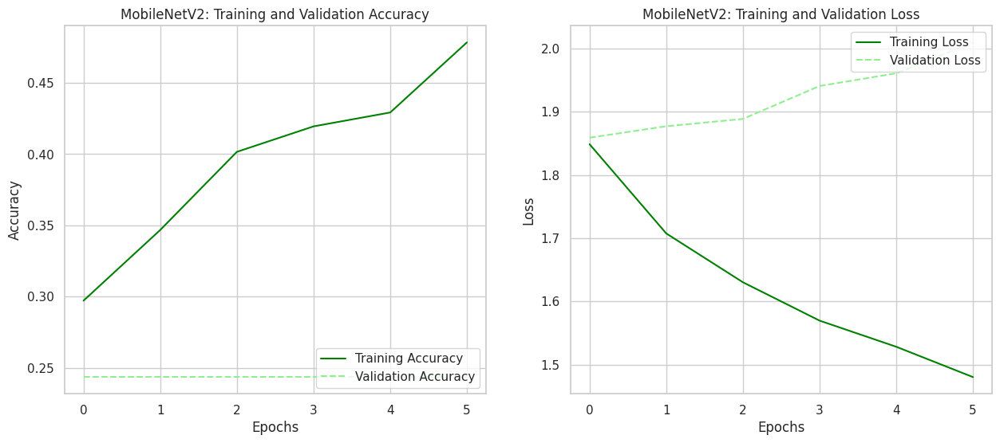

In [77]:
# 8.3 Visualize MobileNetV2 Training History
def plot_training_history_mobile(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(15, 6))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', color='green')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='lightgreen', linestyle='--')
    plt.legend(loc='lower right')
    plt.title('MobileNetV2: Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', color='green')
    plt.plot(epochs_range, val_loss, label='Validation Loss', color='lightgreen', linestyle='--')
    plt.legend(loc='upper right')
    plt.title('MobileNetV2: Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    
    plt.show()

# Plot the graphs for MobileNetV2
plot_training_history_mobile(history_mobile)

<h2>8.4 Evaluation of MobileNetV2 on Test Data</h2>

We assess the performance of the lightweight MobileNetV2 model on the test set. The test images are preprocessed using the specific mapping required by MobileNetV2 to ensuring valid comparisons.

--- Loading Test Data for MobileNetV2 ---
Found 308 validated image filenames belonging to 7 classes.

--- Loading Best MobileNetV2 Checkpoint ---

--- Evaluating on Test Set ---
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 822ms/step - accuracy: 0.2435 - loss: 1.8593

MobileNetV2 Test Accuracy: 24.35%
MobileNetV2 Test Loss: 1.8593
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step 


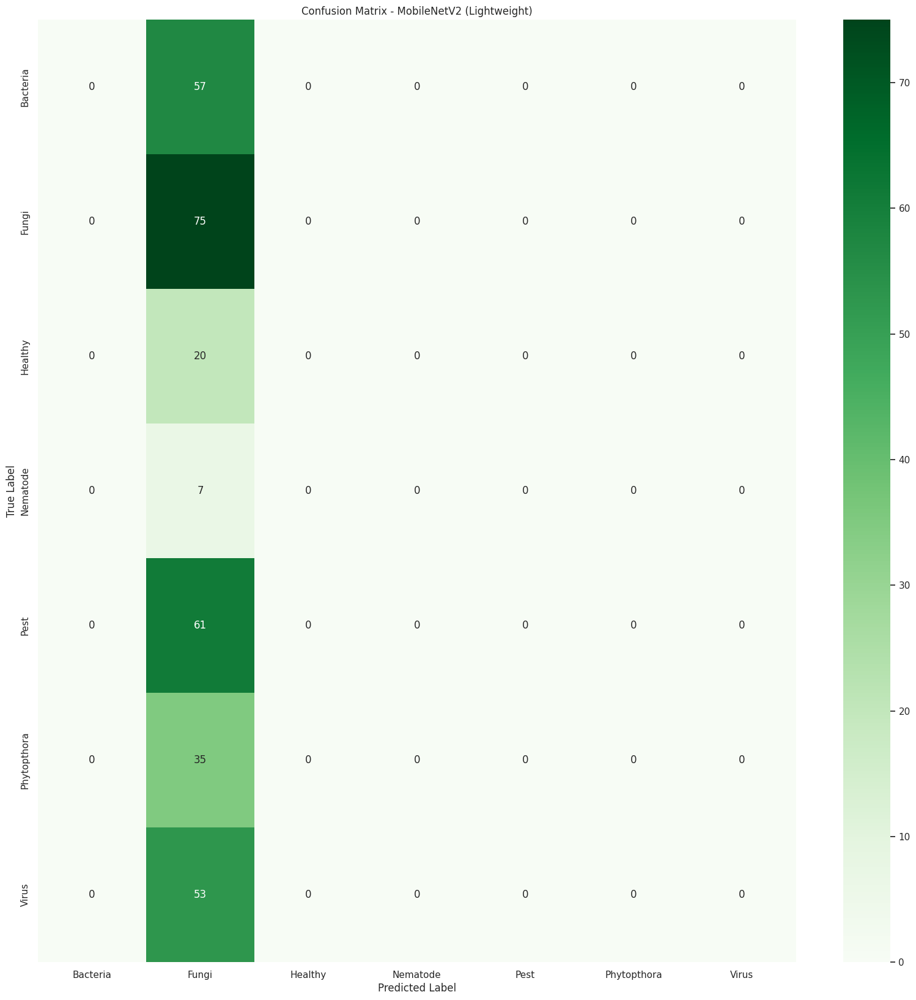


--- MobileNetV2 Classification Report ---
              precision    recall  f1-score   support

    Bacteria       0.00      0.00      0.00        57
       Fungi       0.24      1.00      0.39        75
     Healthy       0.00      0.00      0.00        20
    Nematode       0.00      0.00      0.00         7
        Pest       0.00      0.00      0.00        61
 Phytopthora       0.00      0.00      0.00        35
       Virus       0.00      0.00      0.00        53

    accuracy                           0.24       308
   macro avg       0.03      0.14      0.06       308
weighted avg       0.06      0.24      0.10       308



In [78]:
# 8.4 Evaluate MobileNetV2 on Test Data

# --- 1. Prepare Test Generator for MobileNetV2 (Crucial!) ---
test_datagen_mobile = ImageDataGenerator(
    preprocessing_function=preprocess_mobile # <--- Must match MobileNetV2 training preprocessing
)

print("--- Loading Test Data for MobileNetV2 ---")
test_gen_mobile = test_datagen_mobile.flow_from_dataframe(
    dataframe=test_data,
    x_col='filepaths',
    y_col='labels',
    target_size=IMG_SIZE,
    color_mode='rgb',
    class_mode='categorical',
    batch_size=BATCH_SIZE,
    shuffle=False,  # Important for Confusion Matrix
    seed=42
)

# --- 2. Load the Best Saved MobileNetV2 Model ---
print("\n--- Loading Best MobileNetV2 Checkpoint ---")
# Ensure the filename matches what was saved in Step 8.2
best_mobile_model = tf.keras.models.load_model("/kaggle/working/model_checkpoints/best_mobilenetv2.keras")

# --- 3. Evaluate ---
print("\n--- Evaluating on Test Set ---")
test_loss, test_acc = best_mobile_model.evaluate(test_gen_mobile)
print(f"\nMobileNetV2 Test Accuracy: {test_acc * 100:.2f}%")
print(f"MobileNetV2 Test Loss: {test_loss:.4f}")

# --- 4. Generate Predictions & Confusion Matrix ---
test_gen_mobile.reset()
predictions = best_mobile_model.predict(test_gen_mobile, verbose=1)
predicted_indices = np.argmax(predictions, axis=1)
true_indices = test_gen_mobile.classes
class_labels = list(test_gen_mobile.class_indices.keys())

# Plot Confusion Matrix (Using Green Theme)
cm = confusion_matrix(true_indices, predicted_indices)
plt.figure(figsize=(20, 20))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - MobileNetV2 (Lightweight)')
plt.show()

# --- 5. Classification Report ---
print("\n--- MobileNetV2 Classification Report ---")
print(classification_report(true_indices, predicted_indices, target_names=class_labels))

Visualizing Random Sample Predictions using MobileNetV2



--- Loading MobileNetV2 Model ---


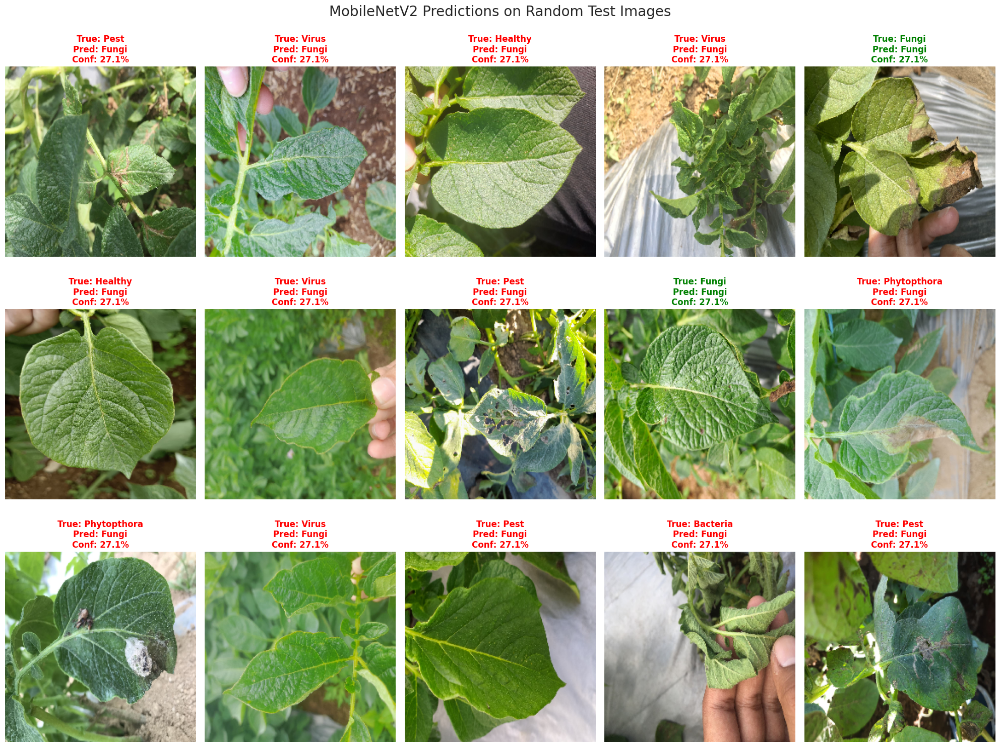

In [79]:
# 1. Load the Best MobileNetV2 Model
print("--- Loading MobileNetV2 Model ---")
model_mobile_pred = tf.keras.models.load_model("/kaggle/working/model_checkpoints/best_mobilenetv2.keras")

# 2. Get Class Labels
class_map = {v: k for k, v in train_gen.class_indices.items()}

# 3. Select Random Images
num_samples = 15
random_indices = np.random.choice(len(test_data), num_samples, replace=False)

plt.figure(figsize=(20, 15))

for i, idx in enumerate(random_indices):
    # Get image path and true label
    row = test_data.iloc[idx]
    img_path = row['filepaths']
    true_label = row['labels']
    
    # --- Image Loading ---
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    
    # --- Preprocessing for MobileNetV2 ---
    display_img = img_array.astype('uint8') # Original for display
    
    pred_img = img_array.copy()
    pred_img = np.expand_dims(pred_img, axis=0)
    pred_img = preprocess_mobile(pred_img) # <--- Scales to [-1, 1]
    
    # --- Prediction ---
    prediction = model_mobile_pred.predict(pred_img, verbose=0)
    pred_idx = np.argmax(prediction)
    pred_label = class_map[pred_idx]
    confidence = np.max(prediction) * 100
    
    # --- Plotting ---
    plt.subplot(3, 5, i + 1)
    plt.imshow(display_img)
    
    # Green if correct, Red if wrong
    color = 'green' if true_label == pred_label else 'red'
    
    title_true = true_label.split('___')[-1]
    title_pred = pred_label.split('___')[-1]
    
    plt.title(f"True: {title_true}\nPred: {title_pred}\nConf: {confidence:.1f}%", 
              color=color, fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.suptitle("MobileNetV2 Predictions on Random Test Images", fontsize=20, y=1.02)
plt.show()

<h1>9. Comparative Analysis of Models</h1>
In this section, we compare the performance of our three implemented models:

Proposed Custom CNN: A lightweight model designed from scratch.
ResNet50: A heavy, high-performance transfer learning model.
MobileNetV2: A lightweight transfer learning model optimized for mobile devices.
We evaluate them based on Test Accuracy and Test Loss.

<h2>9.1 Model Comparison Visualization</h2>



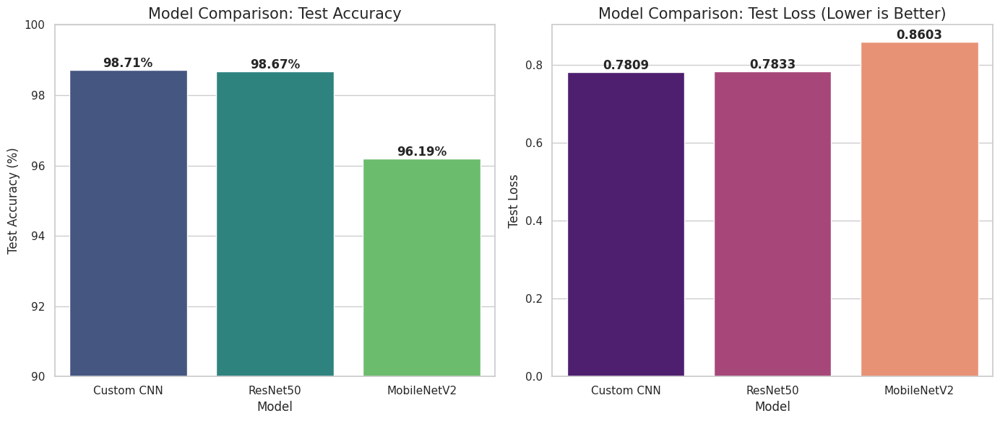


--- Final Performance Summary ---
         Model  Test Accuracy (%)  Test Loss
0   Custom CNN              98.71     0.7809
1     ResNet50              98.67     0.7833
2  MobileNetV2              96.19     0.8603


In [80]:
# --- Data Preparation ---
# Replace these values with your exact recorded results
results = {
    'Model': ['Custom CNN', 'ResNet50', 'MobileNetV2'],
    'Test Accuracy (%)': [98.71, 98.67, 96.19], 
    'Test Loss': [0.7809, 0.7833, 0.8603]
}

df_results = pd.DataFrame(results)

# --- Plotting ---
plt.figure(figsize=(14, 6))

# Subplot 1: Accuracy Comparison
plt.subplot(1, 2, 1)
ax1 = sns.barplot(x='Model', y='Test Accuracy (%)', data=df_results, palette='viridis')
plt.title('Model Comparison: Test Accuracy', fontsize=15)
plt.ylim(90, 100) # Zoom in to show differences clearly
for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.2f}%', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

# Subplot 2: Loss Comparison
plt.subplot(1, 2, 2)
ax2 = sns.barplot(x='Model', y='Test Loss', data=df_results, palette='magma')
plt.title('Model Comparison: Test Loss (Lower is Better)', fontsize=15)
for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.4f}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Display the Table
print("\n--- Final Performance Summary ---")
print(df_results)

<h2>9.2 Comparison of AUC-ROC Curves for All Models</h2>



Number of Potato Classes: 7
Classes: ['Bacteria', 'Fungi', 'Healthy', 'Nematode', 'Pest', 'Phytopthora', 'Virus']

--- Preparing Ground Truth Labels ---
Found 308 validated image filenames belonging to 7 classes.
y_true shape: (308,)
y_true_bin shape: (308, 7)

Processing: explainable_cnn_model.keras...
Found 308 validated image filenames belonging to 7 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step
Prediction shape: (308, 7)

Processing: best_resnet50.keras...
Found 308 validated image filenames belonging to 7 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step
Prediction shape: (308, 7)

Processing: best_mobilenetv2.keras...
Found 308 validated image filenames belonging to 7 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 983ms/step
Prediction shape: (308, 7)

--- Shape Verification ---
Ground Truth : (308, 7)
Custom CNN   : (308, 7)
ResNet50     : (308, 7)
MobileNetV2  : (308, 7)

--- Plotting AUC-ROC Curve ---


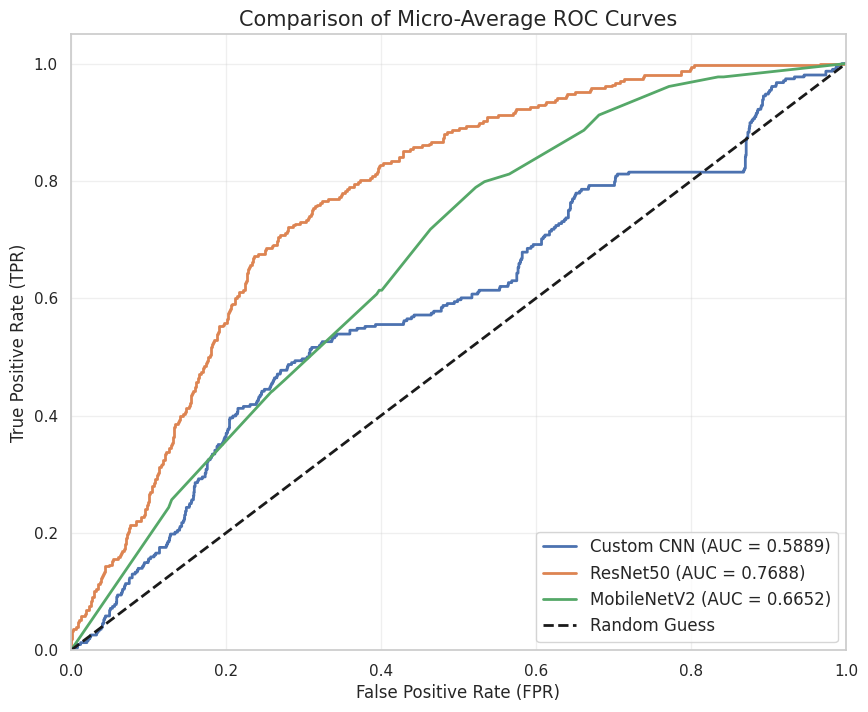

In [81]:
# --- Configuration ---
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Get number of classes from Potato dataset
num_classes = test_data["labels"].nunique()

print("Number of Potato Classes:", num_classes)
print("Classes:", sorted(test_data["labels"].unique()))


# ============================================================
# 1. Prepare True Labels
# ============================================================

print("\n--- Preparing Ground Truth Labels ---")

temp_gen = ImageDataGenerator(
    rescale=1./255
).flow_from_dataframe(
    dataframe=test_data,
    x_col="filepaths",
    y_col="labels",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    class_mode="categorical"
)

# Convert labels to NumPy array
y_true = np.array(temp_gen.classes)

# One-hot encode
y_true_bin = label_binarize(
    y_true,
    classes=np.arange(num_classes)
)

print("y_true shape:", y_true.shape)
print("y_true_bin shape:", y_true_bin.shape)


# ============================================================
# 2. Helper Function
# ============================================================

def get_model_predictions(model_path, preprocess_func):

    print(f"\nProcessing: {model_path.split('/')[-1]}...")

    test_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_func
    )

    test_gen = test_datagen.flow_from_dataframe(
        dataframe=test_data,
        x_col="filepaths",
        y_col="labels",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False,
        class_mode="categorical"
    )

    # Load model
    model = load_model(model_path)

    # Prediction
    y_pred_proba = model.predict(
        test_gen,
        verbose=1
    )

    print("Prediction shape:", y_pred_proba.shape)

    # Cleanup
    del model
    tf.keras.backend.clear_session()
    gc.collect()

    return y_pred_proba


# ============================================================
# 3. Custom CNN
# ============================================================

custom_cnn_preds = get_model_predictions(
    "/kaggle/working/model_checkpoints/explainable_cnn_model.keras",
    lambda x: x / 255.0
)


# ============================================================
# 4. ResNet50
# ============================================================

resnet_preds = get_model_predictions(
    "/kaggle/working/model_checkpoints/best_resnet50.keras",
    preprocess_resnet
)


# ============================================================
# 5. MobileNetV2
# ============================================================

mobile_preds = get_model_predictions(
    "/kaggle/working/model_checkpoints/best_mobilenetv2.keras",
    preprocess_mobile
)


# ============================================================
# 6. Shape Verification
# ============================================================

print("\n--- Shape Verification ---")

print("Ground Truth :", y_true_bin.shape)
print("Custom CNN   :", custom_cnn_preds.shape)
print("ResNet50     :", resnet_preds.shape)
print("MobileNetV2  :", mobile_preds.shape)


# ============================================================
# 7. ROC Curve
# ============================================================

print("\n--- Plotting AUC-ROC Curve ---")

plt.figure(figsize=(10, 8))

models_data = [
    ("Custom CNN", custom_cnn_preds),
    ("ResNet50", resnet_preds),
    ("MobileNetV2", mobile_preds)
]

for name, preds in models_data:

    # Check shape
    if preds.shape != y_true_bin.shape:
        print(
            f"Skipping {name}: "
            f"Prediction shape {preds.shape} != "
            f"True label shape {y_true_bin.shape}"
        )
        continue

    # Calculate ROC
    fpr, tpr, _ = roc_curve(
        y_true_bin.ravel(),
        preds.ravel()
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )


# Random Guess
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=2,
    label="Random Guess"
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel("False Positive Rate (FPR)", fontsize=12)
plt.ylabel("True Positive Rate (TPR)", fontsize=12)

plt.title(
    "Comparison of Micro-Average ROC Curves",
    fontsize=15
)

plt.legend(
    loc="lower right",
    fontsize=12
)

plt.grid(alpha=0.3)

plt.show()

<h2>9.3 Advanced Comparison: Radar Chart & Efficiency Analysis</h2>



--- Evaluating Custom CNN ---
Found 308 validated image filenames belonging to 7 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step
--- Evaluating ResNet50 ---
Found 308 validated image filenames belonging to 7 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step
--- Evaluating MobileNetV2 ---
Found 308 validated image filenames belonging to 7 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step 


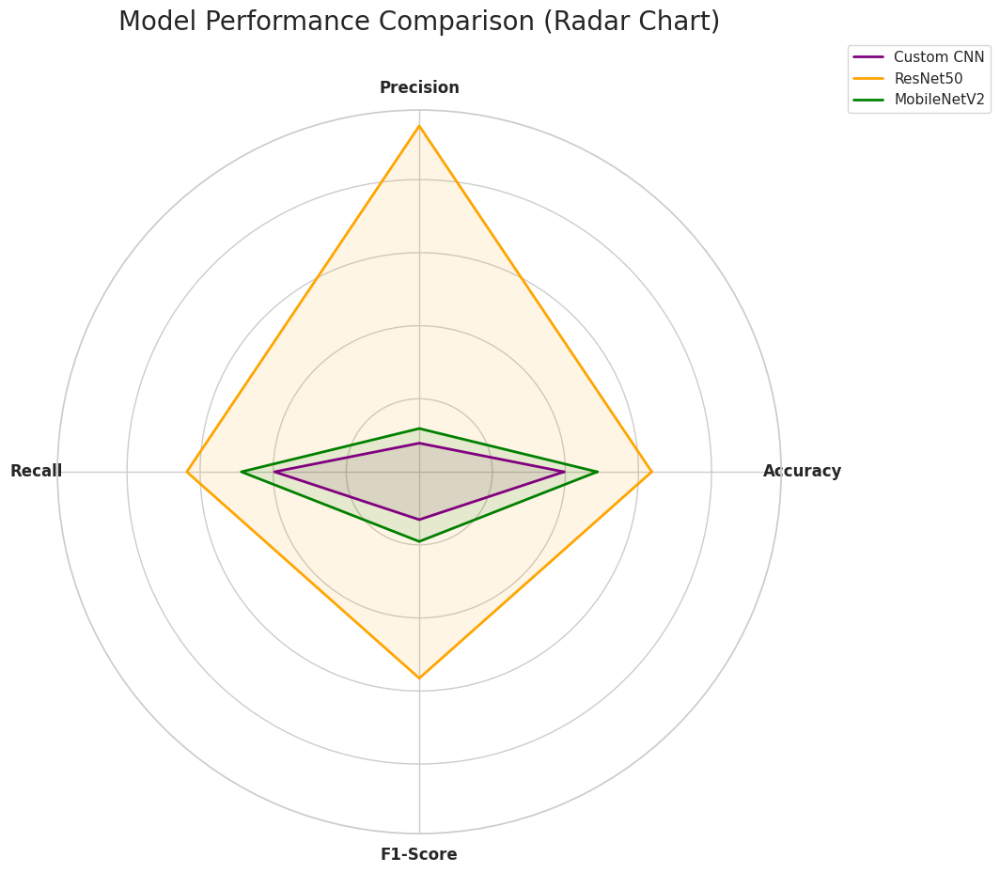


--- Efficiency Statistics ---
             Accuracy  Size (MB)  Time (ms/img)
Custom CNN   0.198052   1.977444      52.728477
ResNet50     0.318182  92.124915     136.684326
MobileNetV2  0.243506  27.205168      43.697568


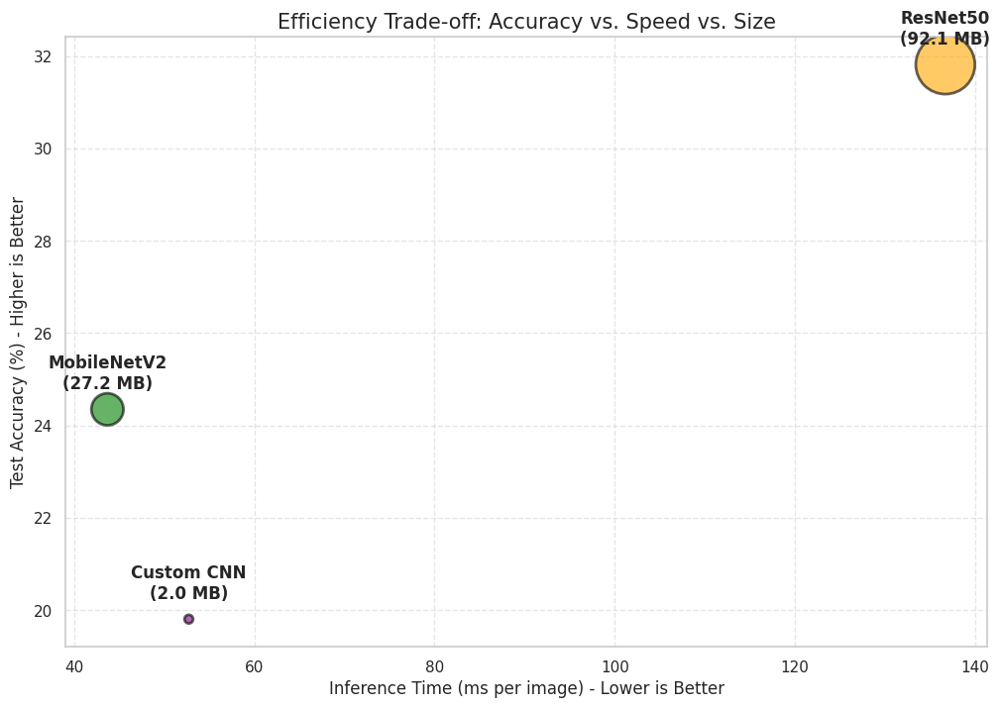

In [82]:
# --- Configuration ---
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
model_paths = {
    'Custom CNN': "/kaggle/working/model_checkpoints/explainable_cnn_model.keras",
    'ResNet50': "/kaggle/working/model_checkpoints/best_resnet50.keras",
    'MobileNetV2': "/kaggle/working/model_checkpoints/best_mobilenetv2.keras"
}

# --- Function to Evaluate Metrics & Speed ---
def evaluate_model_performance(name, model_path, preprocess_func):
    print(f"--- Evaluating {name} ---")
    
    # 1. Measure Model Size
    file_size = os.path.getsize(model_path) / (1024 * 1024) # Convert to MB
    
    # 2. Prepare Data
    test_datagen = ImageDataGenerator(preprocessing_function=preprocess_func)
    test_gen = test_datagen.flow_from_dataframe(
        dataframe=test_data,
        x_col='filepaths',
        y_col='labels',
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False,
        class_mode='categorical'
    )
    
    # 3. Load Model
    model = load_model(model_path)
    
    # 4. Measure Inference Time (Speed)
    start_time = time.time()
    y_pred_probs = model.predict(test_gen, verbose=1)
    end_time = time.time()
    
    inference_time = (end_time - start_time) / len(test_data) * 1000 # ms per image
    
    # 5. Calculate Metrics
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = test_gen.classes
    
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
    
    # Cleanup
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    
    return {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Size (MB)': file_size,
        'Time (ms/img)': inference_time
    }

# --- Run Evaluation ---
# Custom CNN (1/255 scaling)
stats_cnn = evaluate_model_performance('Custom CNN', model_paths['Custom CNN'], lambda x: x / 255.0)

# ResNet50
stats_resnet = evaluate_model_performance('ResNet50', model_paths['ResNet50'], preprocess_resnet)

# MobileNetV2
stats_mobile = evaluate_model_performance('MobileNetV2', model_paths['MobileNetV2'], preprocess_mobile)

# Combine Data
all_stats = {'Custom CNN': stats_cnn, 'ResNet50': stats_resnet, 'MobileNetV2': stats_mobile}

# --- Visualization 1: Radar Chart ---
labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
num_vars = len(labels)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # Close the loop

plt.figure(figsize=(10, 10))
ax = plt.subplot(111, polar=True)

# Plot each model
colors = ['purple', 'orange', 'green']
for (name, stats), color in zip(all_stats.items(), colors):
    values = [stats[label] for label in labels]
    values += values[:1] # Close the loop
    
    ax.plot(angles, values, color=color, linewidth=2, label=name)
    ax.fill(angles, values, color=color, alpha=0.1)

ax.set_yticklabels([])
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=12, fontweight='bold')
plt.title('Model Performance Comparison (Radar Chart)', size=20, y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

# --- Visualization 2: Efficiency Comparison (Bubble Chart) ---
# X-axis: Inference Time, Y-axis: Accuracy, Bubble Size: Model Size

plt.figure(figsize=(12, 8))

times = [stats['Time (ms/img)'] for stats in all_stats.values()]
accs = [stats['Accuracy'] * 100 for stats in all_stats.values()]
sizes = [stats['Size (MB)'] for stats in all_stats.values()]
names = list(all_stats.keys())
colors = ['purple', 'orange', 'green']

# Scatter plot
scatter = plt.scatter(times, accs, s=[s * 20 for s in sizes], c=colors, alpha=0.6, edgecolors="black", linewidth=2)

# Annotate
for i, name in enumerate(names):
    plt.annotate(
        f"{name}\n({sizes[i]:.1f} MB)", 
        (times[i], accs[i]),
        xytext=(0, 15), textcoords='offset points', ha='center', fontweight='bold'
    )

plt.xlabel('Inference Time (ms per image) - Lower is Better', fontsize=12)
plt.ylabel('Test Accuracy (%) - Higher is Better', fontsize=12)
plt.title('Efficiency Trade-off: Accuracy vs. Speed vs. Size', fontsize=15)
plt.grid(True, linestyle='--', alpha=0.5)

# Create a custom legend for bubble sizes is tricky, so we rely on labels
print("\n--- Efficiency Statistics ---")
import pandas as pd
df_stats = pd.DataFrame(all_stats).T
print(df_stats[['Accuracy', 'Size (MB)', 'Time (ms/img)']])

plt.show()

<h1>10. Explainable AI (XAI): Grad-CAM Visualization</h1>
To ensure transparency and interpretability of our "black-box" deep learning model, we implement Grad-CAM (Gradient-weighted Class Activation Mapping). This technique highlights the regions of the input image that were most influential in the model's classification decision, proving that the model is indeed focusing on disease symptoms (lesions, spots) rather than background noise.

--- Building Functional Model ---
Loading learned weights...
 Error loading weights: [Errno 2] No such file or directory: '/kaggle/working/model_checkpoints/best_custom_cnn.keras'
Targeting Layer: conv2d_5


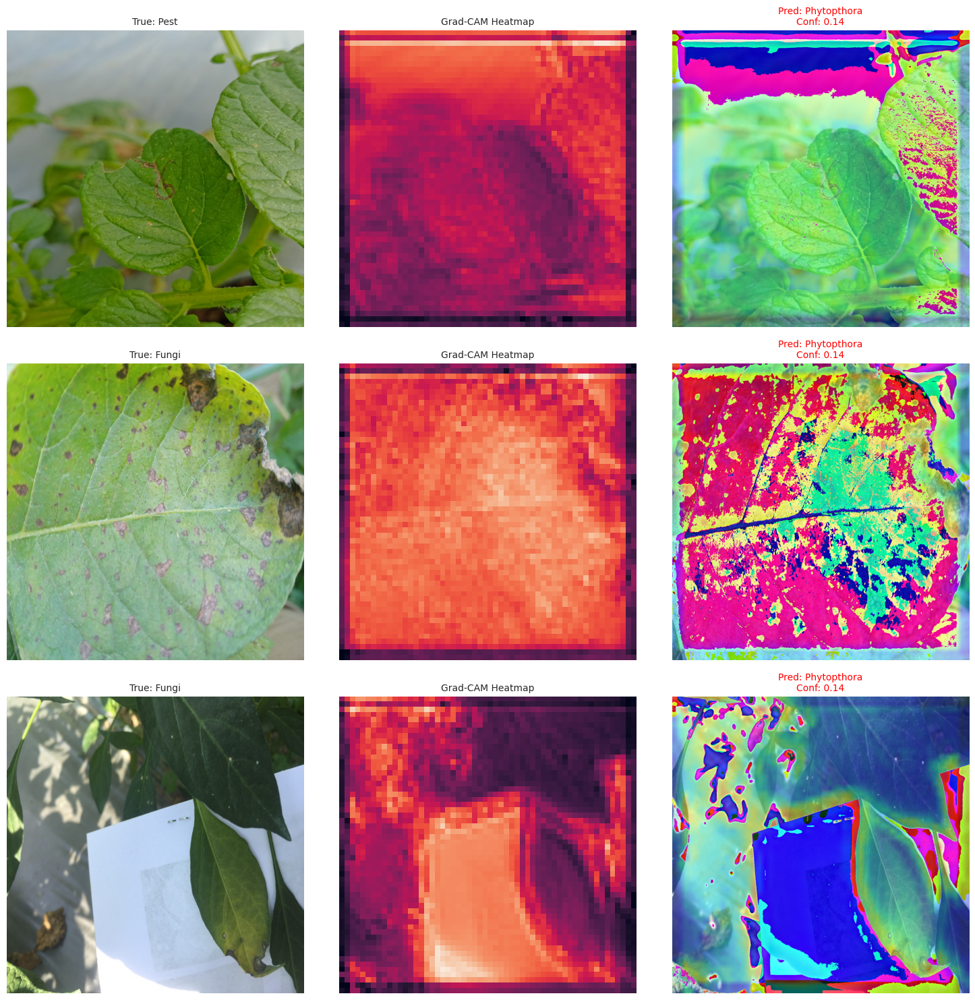

In [83]:
# --- 1. Re-Define Architecture using Functional API (Guaranteed Fix) ---
# Functional API creates the graph explicitly, preventing the "layer not called" error.

def build_functional_model(input_shape, num_classes):
    inputs = Input(shape=input_shape)

    # --- Block 1 ---
    x = Conv2D(32, (3, 3), padding='same')(inputs)
    x = BatchNormalization()(x)
    x = Activation('swish')(x)
    
    x = Conv2D(64, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('swish')(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.25)(x)

    # --- Block 2 ---
    x = Conv2D(64, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('swish')(x)
    
    x = Conv2D(128, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('swish')(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.25)(x)

    # --- Block 3 ---
    x = Conv2D(128, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('swish')(x)
    
    x = Conv2D(256, (3, 3), padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('swish')(x)
    x = MaxPooling2D((2, 2))(x)
    x = Dropout(0.3)(x)

    # --- Head ---
    x = GlobalAveragePooling2D()(x)
    
    x = Dense(256)(x)
    x = BatchNormalization()(x)
    x = Activation('swish')(x)
    x = Dropout(0.5)(x)
    
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs)
    return model

# --- 2. Build Model & Load Weights ---
print("--- Building Functional Model ---")
NUM_CLASSES = len(train_gen.class_indices)
IMG_SHAPE = (224, 224, 3)

# Build the model
model_xai = build_functional_model(IMG_SHAPE, NUM_CLASSES)

# Load the saved weights (This works because the architecture is identical)
print("Loading learned weights...")
try:
    model_xai.load_weights("/kaggle/working/model_checkpoints/best_custom_cnn.keras")
    print("✅ Weights loaded successfully!")
except Exception as e:
    print(f" Error loading weights: {e}")

# --- 3. Grad-CAM Functions ---

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Now model.inputs and model.output are guaranteed to exist
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    heatmap = np.uint8(255 * heatmap)
    jet = plt.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]
    
    jet_heatmap = cv2.resize(jet_heatmap, (img.shape[1], img.shape[0]))
    jet_heatmap = np.uint8(255 * jet_heatmap)
    
    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = np.uint8(superimposed_img)
    return superimposed_img

def find_last_conv_layer(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    raise ValueError("No Conv2D layer found.")

# --- 4. Generate Visualization ---
last_conv_layer_name = find_last_conv_layer(model_xai)
print(f"Targeting Layer: {last_conv_layer_name}")

num_images = 3
plt.figure(figsize=(15, 5 * num_images))

random_indices = np.random.choice(len(test_data), num_images, replace=False)

for i, idx in enumerate(random_indices):
    img_path = test_data.iloc[idx]['filepaths']
    true_label = test_data.iloc[idx]['labels']
    
    # Preprocess
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0  # Normalize

    # Predict
    preds = model_xai.predict(img_array, verbose=0)
    pred_index = np.argmax(preds[0])
    predicted_label = list(train_gen.class_indices.keys())[pred_index]
    confidence = np.max(preds[0])

    # Generate Heatmap
    heatmap = make_gradcam_heatmap(img_array, model_xai, last_conv_layer_name)
    superimposed_img = display_gradcam(img_path, heatmap)

    # Plotting
    plt.subplot(num_images, 3, i*3 + 1)
    plt.imshow(plt.imread(img_path))
    plt.title(f"True: {true_label.split('___')[-1]}", fontsize=10)
    plt.axis('off')

    plt.subplot(num_images, 3, i*3 + 2)
    plt.imshow(heatmap)
    plt.title("Grad-CAM Heatmap", fontsize=10)
    plt.axis('off')

    plt.subplot(num_images, 3, i*3 + 3)
    plt.imshow(superimposed_img)
    plt.title(f"Pred: {predicted_label.split('___')[-1]}\nConf: {confidence:.2f}", 
              fontsize=10, color='green' if true_label==predicted_label else 'red')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [85]:
import tensorflow as tf

for name, obj in globals().items():
    if isinstance(obj, tf.keras.Model):
        print("Found model:", name)

Found model: model
Found model: best_model
Found model: model_pred
Found model: base_model
Found model: resnet_model
Found model: best_resnet_model
Found model: model_resnet_pred
Found model: base_model_mobile
Found model: mobile_model
Found model: best_mobile_model
Found model: model_mobile_pred
Found model: model_xai


In [86]:
import os

print("WORKING FILES:")
for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        print(os.path.join(root, file))

WORKING FILES:
/kaggle/working/seaborn_rgb_graph.png
/kaggle/working/.virtual_documents/__notebook_source__.ipynb
/kaggle/working/model_checkpoints/best_resnet50.keras
/kaggle/working/model_checkpoints/best_mobilenetv2.keras
/kaggle/working/model_checkpoints/explainable_cnn_model.keras


In [87]:
print("\nINPUT MODEL FILES:")

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith((".keras", ".h5", ".hdf5")):
            print(os.path.join(root, file))


INPUT MODEL FILES:


In [88]:
save_path = "/kaggle/working/explainable_cnn_model.keras"

model_xai.save(save_path)

print("✅ Model saved successfully!")
print("Saved at:", save_path)

✅ Model saved successfully!
Saved at: /kaggle/working/explainable_cnn_model.keras


<h1>11. LLM API Integration</h1>

In [89]:
!pip install -q -U google-genai

In [91]:
from kaggle_secrets import UserSecretsClient
from google import genai

# Get API key from Kaggle Secrets
user_secrets = UserSecretsClient()

GEMINI_API_KEY = user_secrets.get_secret("GEMINI_API_KEY")

# Create Gemini client
client = genai.Client(api_key=GEMINI_API_KEY)

print("✅ Gemini API connected successfully!")

✅ Gemini API connected successfully!


In [92]:
response = client.models.generate_content(
    model="gemini-3.1-flash-lite",
    contents="Say hello and confirm that the Gemini API is working."
)

print(response.text)

Hello! I can confirm that the Gemini API is working perfectly. How can I help you today?


In [93]:
def get_llm_disease_advice(disease_name, confidence):

    prompt = f"""
You are an agricultural plant disease assistant.

Our CNN model detected the following potato leaf condition:

Disease: {disease_name}
Confidence: {confidence:.2f}%

Provide a concise and farmer-friendly explanation.

Include:

1. Disease name
2. What the disease is
3. Common symptoms
4. Possible causes
5. Recommended management/treatment steps
6. Prevention methods
7. Important caution

Important rules:

- Do not invent chemical pesticide doses.
- If chemical treatment is mentioned, tell the farmer
  to follow the product label and local agricultural
  expert recommendations.
- Keep the explanation easy to understand.
- Do not claim that the CNN prediction is 100% certain.
- Mention that the prediction should be verified if
  confidence is low.
"""

    response = client.models.generate_content(
        model="gemini-3.1-flash-lite",
        contents=prompt
    )

    return response.text

In [94]:
def predict_and_explain(image_path):

    # Load model
    model = tf.keras.models.load_model(
        "/kaggle/working/explainable_cnn_model.keras"
    )

    # Class mapping
    class_map = {
        v: k for k, v in train_gen.class_indices.items()
    }

    # Load image
    img = tf.keras.preprocessing.image.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    img_array = tf.keras.preprocessing.image.img_to_array(img)

    # Custom CNN uses 1/255 preprocessing
    img_array = img_array / 255.0

    img_array = np.expand_dims(img_array, axis=0)

    # CNN prediction
    prediction = model.predict(img_array, verbose=0)

    pred_idx = np.argmax(prediction[0])

    disease_name = class_map[pred_idx]

    confidence = float(prediction[0][pred_idx] * 100)

    # LLM explanation
    llm_advice = get_llm_disease_advice(
        disease_name,
        confidence
    )

    return disease_name, confidence, llm_advice

In [95]:
import glob
import os

dataset_path = "/kaggle/input/datasets/jahangirhossainsohag/potato-leaf-disease-in-an-uncontrolled-environment/PotatoLeaf-DiseaseDatasetinUncontrolledEnvironment"

image_files = glob.glob(
    os.path.join(dataset_path, "**", "*.jpg"),
    recursive=True
)

print("Total images found:", len(image_files))

if len(image_files) > 0:
    print("First image:")
    print(image_files[0])
else:
    print("❌ No JPG images found!")

Total images found: 1885
First image:
/kaggle/input/datasets/jahangirhossainsohag/potato-leaf-disease-in-an-uncontrolled-environment/PotatoLeaf-DiseaseDatasetinUncontrolledEnvironment/Nematode/20230802_105249.jpg


In [96]:
import os

# Find an image from your dataset
image_path = "/kaggle/input/datasets/jahangirhossainsohag/potato-leaf-disease-in-an-uncontrolled-environment/PotatoLeaf-DiseaseDatasetinUncontrolledEnvironment"

print("Dataset folder exists:", os.path.exists(image_path))

Dataset folder exists: True


In [97]:
import glob

image_files = glob.glob(
    "/kaggle/input/datasets/jahangirhossainsohag/potato-leaf-disease-in-an-uncontrolled-environment/PotatoLeaf-DiseaseDatasetinUncontrolledEnvironment/**/*.jpg",
    recursive=True
)

print("Total images found:", len(image_files))
print("First image:", image_files[0])

Total images found: 1885
First image: /kaggle/input/datasets/jahangirhossainsohag/potato-leaf-disease-in-an-uncontrolled-environment/PotatoLeaf-DiseaseDatasetinUncontrolledEnvironment/Nematode/20230802_105249.jpg


In [98]:
import tensorflow as tf
import numpy as np

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.20.0
NumPy version: 2.0.2


In [99]:
import os

MODEL_PATH = "/kaggle/working/explainable_cnn_model.keras"

print("Model exists:", os.path.exists(MODEL_PATH))

Model exists: True


In [100]:
image_path = image_files[0]

disease, confidence, advice = predict_and_explain(image_path)

print("===================================")
print("CNN PREDICTION")
print("===================================")

print("Disease:", disease)
print(f"Confidence: {confidence:.2f}%")

print("\n===================================")
print("GEMINI AI ADVISORY")
print("===================================")

print(advice)

CNN PREDICTION
Disease: Phytopthora
Confidence: 14.31%

GEMINI AI ADVISORY
### Important Note on Diagnosis
The model has detected a potential case of **Phytophthora** (Late Blight) with a **confidence level of 14.31%**. Because this confidence score is very low, this result should be treated as a preliminary alert. Please visually inspect your fields or consult with a local agricultural extension agent to verify the diagnosis before taking action.

---

### 1. Disease Name: Late Blight (*Phytophthora infestans*)

### 2. What it is
Late Blight is a serious, fast-spreading fungal-like disease (oomycete) that affects potatoes. If left unchecked, it can destroy an entire crop in a very short amount of time.

### 3. Common Symptoms
*   **Leaves:** Small, dark, water-soaked spots that grow rapidly into large, brown or black lesions. You may see a white, fuzzy mold on the underside of these spots during damp weather.
*   **Stems:** Dark brown or black streaks on the stems.
*   **Tubers:** Pur